# Previsão do preço do petróleo Brent em dólar
**Prova Substitutiva · Data Analytics · POSTECH (Fase 4)** · Vinicius de Marchi Franciscon

**Parte 1: análise exploratória. Parte 2: modelagem.** A história que os dados contam, em quatro frases:
1. O preço do petróleo vive de **ciclos e choques**.
2. O mercado alterna entre **fases estáveis e turbulentas**, e a agitação de hoje tende a continuar amanhã.
3. **Dólar e estoques** ajudam pouco a explicar os próximos dias.
4. **"Amanhã = hoje"** é uma boa âncora para o preço. O que dá para prever é a **agitação**.

**Mapa:** 1 Dados · 2 O preço · 3 Mercado estável ou turbulento · 4 Dólar e estoques · 5 Amanhã = hoje? · 6 O que levamos para a modelagem · 7 Preparando a modelagem · 8 Modelo 1: agitação · 9 Faixa de preço · 10 Modelo 2: sobe ou cai · 11 SHAP · 12 Previsão de hoje · 13 Conclusão

## 1. Dados

In [1]:
import os, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf

# ---- estilo único para todos os gráficos: cores com significado fixo, título que conta a conclusão, fonte no rodapé
COR = dict(preco="#14365d", dolar="#d98a1a", estoque="#6b4e9b", alta="#2e8b57", queda="#c0392b", neutro="#8a929c", calmo="#4f9d69", agitado="#c0392b", destaque="#e0a100")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10.5, "axes.labelcolor": "#444", "text.color": "#222", "xtick.color": "#555", "ytick.color": "#555",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#bbb", "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e9ed",
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False})
def moldura(figsize, titulo, sub=None, nrows=1, ncols=1, topo=0.76, **kw):
    fig, axs = plt.subplots(nrows, ncols, figsize=figsize, **kw)
    fig.subplots_adjust(top=topo, bottom=0.15, left=0.07, right=0.97, wspace=0.25, hspace=0.35)
    fig.text(0.012, 0.965, titulo, fontsize=15, fontweight="bold", ha="left", va="top")
    if sub: fig.text(0.012, 0.885, sub, fontsize=10.5, color="#666", ha="left", va="top")
    fig.text(0.012, 0.012, "Fonte: Ipeadata, FRED e EIA. Elaboração própria.", fontsize=8.5, color="#999", ha="left", va="bottom")
    return fig, axs
def usd(ax): ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"US$ {v:,.0f}"))
def pct(ax, c=0): ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.{c}f}%".replace(".", ",")))
def br(x, c=1): return f"{x:,.{c}f}".replace(",", "X").replace(".", ",").replace("X", ".")
def nota(ax, x, y, txt, dx=0, dy=0, ha="left", cor="#333", seta=True, size=9.5, caixa=False):
    ax.annotate(txt, (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va="center", fontsize=size, color=cor, arrowprops=dict(arrowstyle="-", color="#aaa", lw=0.8) if seta else None,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5) if caixa else None)

# ---- dados
AQUI = Path(os.getcwd()); BASE = next(p / "00_Base_TC" for p in [AQUI, AQUI.parent] if (p / "00_Base_TC").is_dir())
bruta = pd.read_parquet(BASE / "base_modelagem_diaria.parquet").sort_values("data")
dolar = pd.read_parquet(BASE / "dolar_amplo_fred.parquet").sort_values("data").reset_index(drop=True)
est = pd.read_parquet(BASE / "estoques_crude_eia.parquet").sort_values("semana_ref").reset_index(drop=True)
base = bruta[bruta["data"].dt.dayofweek < 5].reset_index(drop=True)                   # só dias úteis
assert base["data"].is_unique and base["data"].is_monotonic_increasing and base.notna().all().all() and (base["preco_usd"] > 0).all()
assert (base["dolar_data_ref"] < base["data"]).all() and ((base["data"] - base["estoque_semana_ref"]).dt.days >= 6).all()     # dólar e estoque só com o que já era conhecido
df = base[["data", "preco_usd"]].copy(); df["var"] = df["preco_usd"].pct_change() * 100                                          # variação diária, em %
y, D = df["preco_usd"].values, pd.DatetimeIndex(df["data"])
display(pd.DataFrame({"Série": ["Preço do Brent", "Dólar (índice amplo)", "Estoques de petróleo dos EUA"], "Frequência": ["diária (dias úteis)", "diária", "semanal"],
                      "Período": [f"{D.min():%m/%Y} a {D.max():%m/%Y}", "01/2006 a 10/2026", "08/1982 a 09/2026"], "Fonte": ["Ipeadata (US$ por barril)", "Federal Reserve (FRED)", "EIA"]}).style.hide(axis="index"))

Série,Frequência,Período,Fonte
Preço do Brent,diária (dias úteis),01/2006 a 09/2026,Ipeadata (US$ por barril)
Dólar (índice amplo),diária,01/2006 a 10/2026,Federal Reserve (FRED)
Estoques de petróleo dos EUA,semanal,08/1982 a 09/2026,EIA


O preço vem do **Ipeadata**, em dólares por barril. Dólar e estoques entram sempre com defasagem: usamos só o que já era conhecido em cada dia.

## 2. O preço do barril

### 2.1 Os grandes momentos

In [2]:
EV = [("2008-07-03", "Preço recorde do período: US$ 144", "dado da série"), ("2008-09-15", "Quebra do banco Lehman Brothers: crise financeira global", "conhecimento geral"),
      ("2014-11-27", "OPEP decide não reduzir a produção", "conhecimento geral"), ("2016-01-20", "Menor preço do ciclo 2014-16: excesso de petróleo", "dado da série"),
      ("2020-03-06", "Rompimento do acordo da OPEP+ em plena pandemia", "conhecimento geral"), ("2020-04-21", "Menor preço de toda a série: US$ 9", "dado da série"),
      ("2022-02-24", "Rússia invade a Ucrânia", "conhecimento geral"), ("2025-06-13", "Israel ataca o Irã (guerra de 12 dias)", "pesquisa na web"),
      ("2026-03-02", "Guerra com o Irã fecha o Estreito de Ormuz", "pesquisa na web"), ("2026-04-08", "Cessar-fogo entre EUA e Irã", "pesquisa na web")]
ev = pd.DataFrame(EV, columns=["data", "evento", "fonte"]); ev["data"] = pd.to_datetime(ev["data"]); pos = D.searchsorted(ev["data"])
ev["efeito"] = [(y[i + 4] / y[i - 1] - 1) * 100 if i + 4 < len(y) else np.nan for i in pos]                                    # preço 5 dias úteis depois, contra o dia anterior
tabela = pd.DataFrame({"Quando": ev["data"].dt.strftime("%d/%m/%Y"), "O que aconteceu": ev["evento"], "Preço 5 dias úteis depois": ev["efeito"]})
display(tabela.style.hide(axis="index").format({"Preço 5 dias úteis depois": "{:+.0f}%"}, na_rep="—").map(lambda v: "" if pd.isna(v) else ("color:#c0392b;font-weight:600" if v < 0 else "color:#2e8b57;font-weight:600"), subset=["Preço 5 dias úteis depois"]))
print("Datas de 2008 a 2022: conhecimento geral, sem checagem em fonte.")

Quando,O que aconteceu,Preço 5 dias úteis depois
03/07/2008,Preço recorde do período: US$ 144,-5%
15/09/2008,Quebra do banco Lehman Brothers: crise financeira global,-11%
27/11/2014,OPEP decide não reduzir a produção,-12%
20/01/2016,Menor preço do ciclo 2014-16: excesso de petróleo,+6%
06/03/2020,Rompimento do acordo da OPEP+ em plena pandemia,-39%
21/04/2020,Menor preço de toda a série: US$ 9,-13%
24/02/2022,Rússia invade a Ucrânia,+20%
13/06/2025,Israel ataca o Irã (guerra de 12 dias),+13%
02/03/2026,Guerra com o Irã fecha o Estreito de Ormuz,+34%
08/04/2026,Cessar-fogo entre EUA e Irã,-14%


Datas de 2008 a 2022: conhecimento geral, sem checagem em fonte.


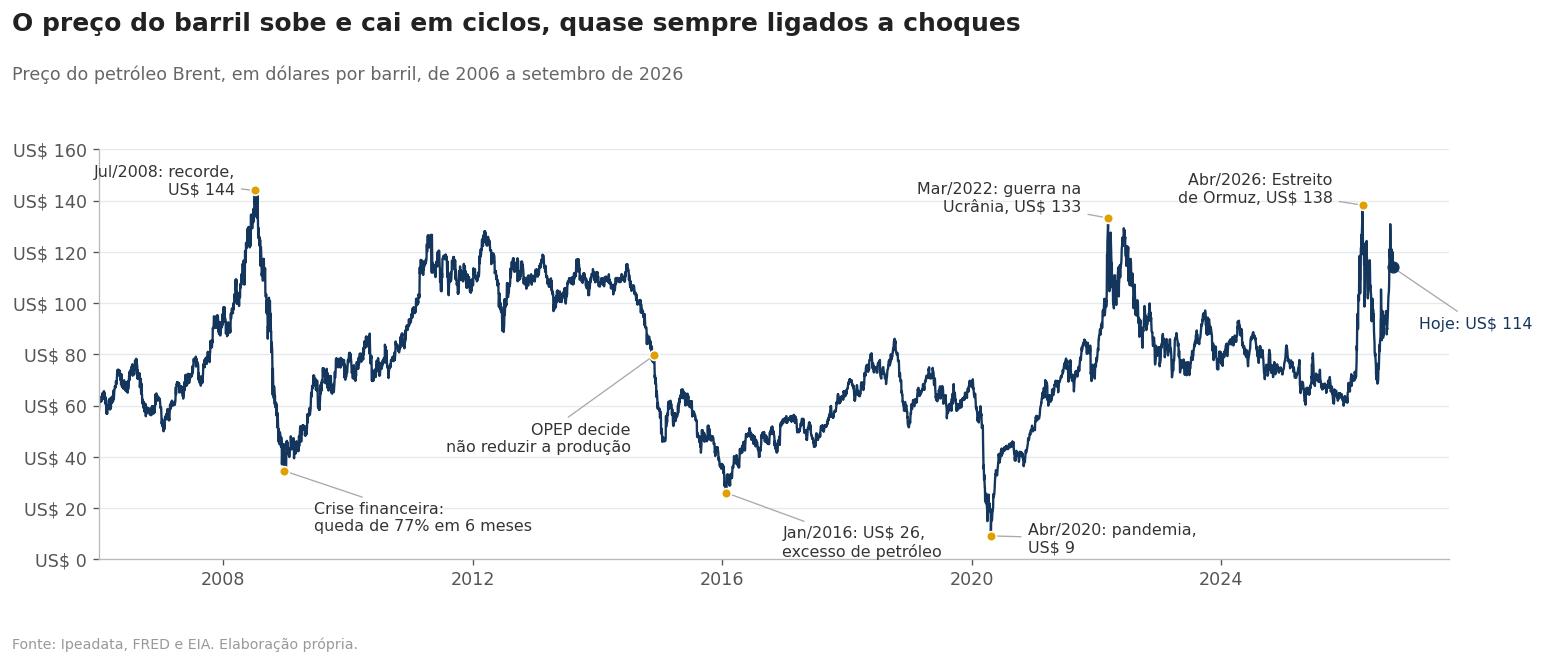

In [3]:
fig, ax = moldura((12.5, 5.6), "O preço do barril sobe e cai em ciclos, quase sempre ligados a choques", "Preço do petróleo Brent, em dólares por barril, de 2006 a setembro de 2026")
ax.plot(D, y, color=COR["preco"], lw=1.4)
marcos = [("2008-07-03", "Jul/2008: recorde,\nUS$ 144", (-12, 6), "right"), ("2008-12-24", "Crise financeira:\nqueda de 77% em 6 meses", (18, -28), "left"), ("2014-11-27", "OPEP decide\nnão reduzir a produção", (-14, -50), "right"),
          ("2016-01-20", "Jan/2016: US$ 26,\nexcesso de petróleo", (34, -30), "left"), ("2020-04-21", "Abr/2020: pandemia,\nUS$ 9", (22, -2), "left"), ("2022-03-08", "Mar/2022: guerra na\nUcrânia, US$ 133", (-16, 12), "right"),
          ("2026-04-07", "Abr/2026: Estreito\nde Ormuz, US$ 138", (-18, 10), "right")]
for dt, txt, off, ha in marcos:
    i = D.get_indexer([pd.Timestamp(dt)], method="nearest")[0]; ax.scatter(D[i], y[i], s=34, color=COR["destaque"], zorder=5, edgecolor="white", linewidth=1)
    nota(ax, D[i], y[i], txt, off[0], off[1], ha)
ax.scatter(D[-1], y[-1], s=40, color=COR["preco"], zorder=5); nota(ax, D[-1], y[-1], f"Hoje: US$ {y[-1]:.0f}", 16, -34, "left", COR["preco"])
usd(ax); ax.set_ylim(0, 160); ax.set_xlim(D[0], D[-1] + pd.Timedelta(days=330)); plt.show()

### 2.2 Ano a ano

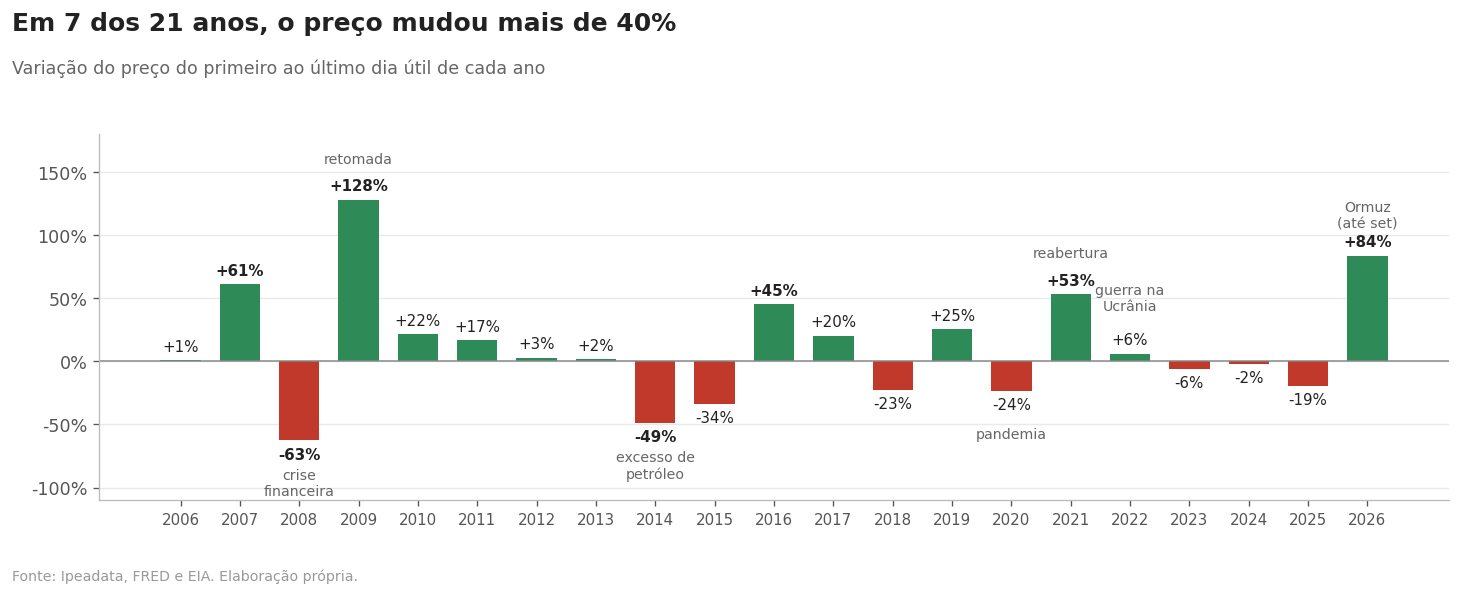

In [4]:
anos = df.assign(ano=D.year).groupby("ano").agg(ini=("preco_usd", "first"), fim=("preco_usd", "last")); anos["var"] = (anos["fim"] / anos["ini"] - 1) * 100
causas = {2008: "crise\nfinanceira", 2009: "retomada", 2014: "excesso de\npetróleo", 2020: "pandemia", 2021: "reabertura", 2022: "guerra na\nUcrânia", 2026: "Ormuz\n(até set)"}
n40 = int((anos["var"].abs() > 40).sum())
fig, ax = moldura((12.5, 5.0), f"Em {n40} dos {len(anos)} anos, o preço mudou mais de 40%", "Variação do preço do primeiro ao último dia útil de cada ano")
ax.bar(anos.index.astype(str), anos["var"], color=[COR["alta"] if v > 0 else COR["queda"] for v in anos["var"]], width=0.68)
for k, (ano, v) in enumerate(anos["var"].items()):
    ax.text(k, v + (5 if v > 0 else -5), f"{v:+.0f}%".replace(".", ","), ha="center", va="bottom" if v > 0 else "top", fontsize=9, fontweight="bold" if abs(v) > 40 else "normal")
    if ano in causas: ax.text(k, v + ((44 if abs(v) < 20 else 32) if v > 0 else -34), causas[ano], ha="center", va="center", fontsize=8.5, color="#666")
ax.axhline(0, color="#888", lw=0.9); ax.set_ylim(-110, 180); pct(ax); ax.tick_params(axis="x", labelsize=9); plt.show()

### 2.3 As grandes quedas

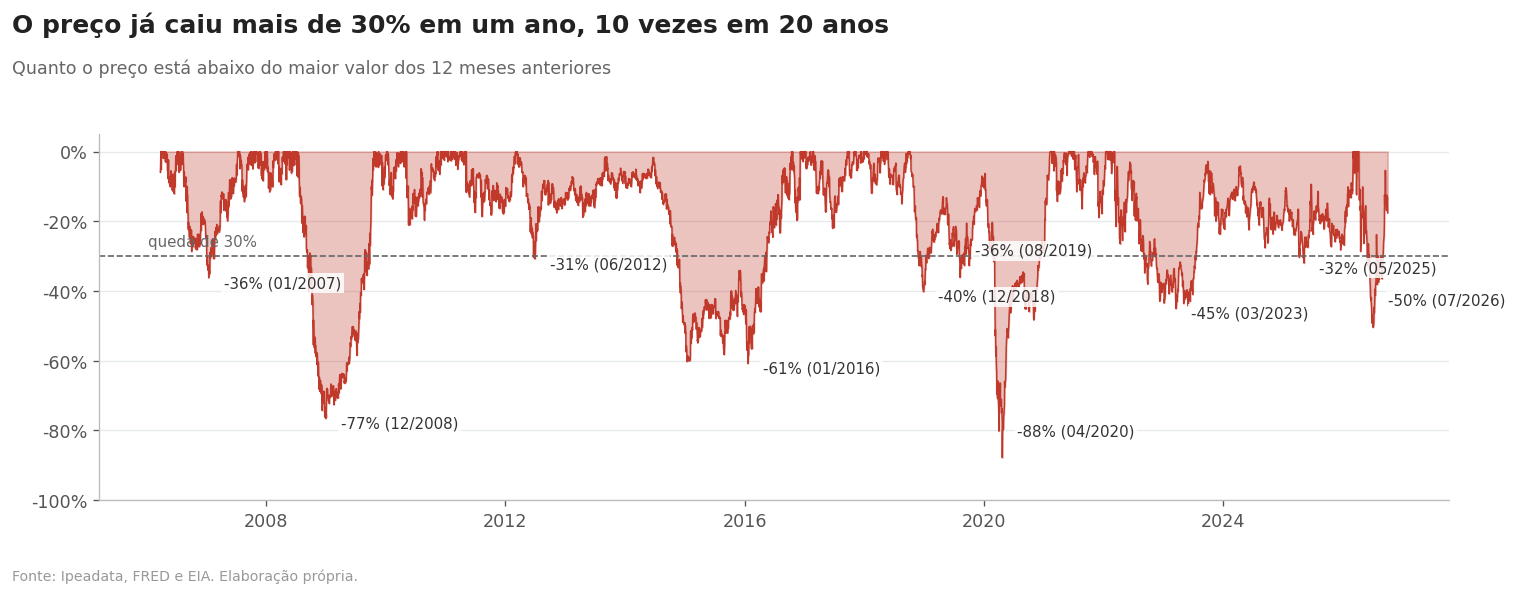

In [5]:
dd = (df["preco_usd"] / df["preco_usd"].rolling(252, min_periods=60).max() - 1) * 100                  # queda contra o maior preço dos últimos 12 meses
abaixo = (dd <= -30).values; fundos = []; i = 0
while i < len(abaixo):
    if abaixo[i]:
        j = i
        while j + 1 < len(abaixo) and abaixo[j + 1:j + 31].any(): j = j + 1 + int(np.argmax(abaixo[j + 1:j + 31]))
        fundos.append(i + int(np.argmin(dd.values[i:j + 1]))); i = j + 1
    else: i += 1
fig, ax = moldura((12.5, 5.0), f"O preço já caiu mais de 30% em um ano, {len(fundos)} vezes em 20 anos", "Quanto o preço está abaixo do maior valor dos 12 meses anteriores")
ax.fill_between(D, dd, 0, color=COR["queda"], alpha=0.30); ax.plot(D, dd, color=COR["queda"], lw=0.9); ax.axhline(-30, color="#666", ls="--", lw=1)
ax.text(D[8], -28, "queda de 30%", fontsize=9, color="#666", va="bottom")
ant = None
for f in fundos:
    perto = ant is not None and f - ant < 350                                  # duas quedas seguidas: o segundo rótulo sobe para não encostar no primeiro
    nota(ax, D[f], dd.iloc[f], f"{dd.iloc[f]:.0f}% ({D[f]:%m/%Y})".replace(".", ","), 9, 16 if perto else -3, "left", seta=False, size=9, caixa=True); ant = f
pct(ax); ax.set_ylim(-100, 5); plt.show()

**O que vemos**
- O preço oscila entre **recordes** (US$ 144 em 2008) e **colapsos** (US$ 9 em 2020), quase sempre depois de um choque.
- Quedas de **30% ou mais em um ano** aconteceram várias vezes em 20 anos (cada uma aparece no gráfico). As maiores: 2020 (−88%), 2008 (−77%) e 2015-16 (−61%).
- Em 2026 o preço foi de US$ 62 a US$ 138 e voltou a US$ 114: a história mais recente também é de choque.

## 3. Mercado estável ou turbulento?

Chamamos de **agitação** o quanto o preço sobe ou desce, em média, por dia nas **últimas 6 semanas**. Dividimos o tempo em três fases: **estável** (menos de 1,5% ao dia), **moderado** e **turbulento** (mais de 3,5% ao dia).

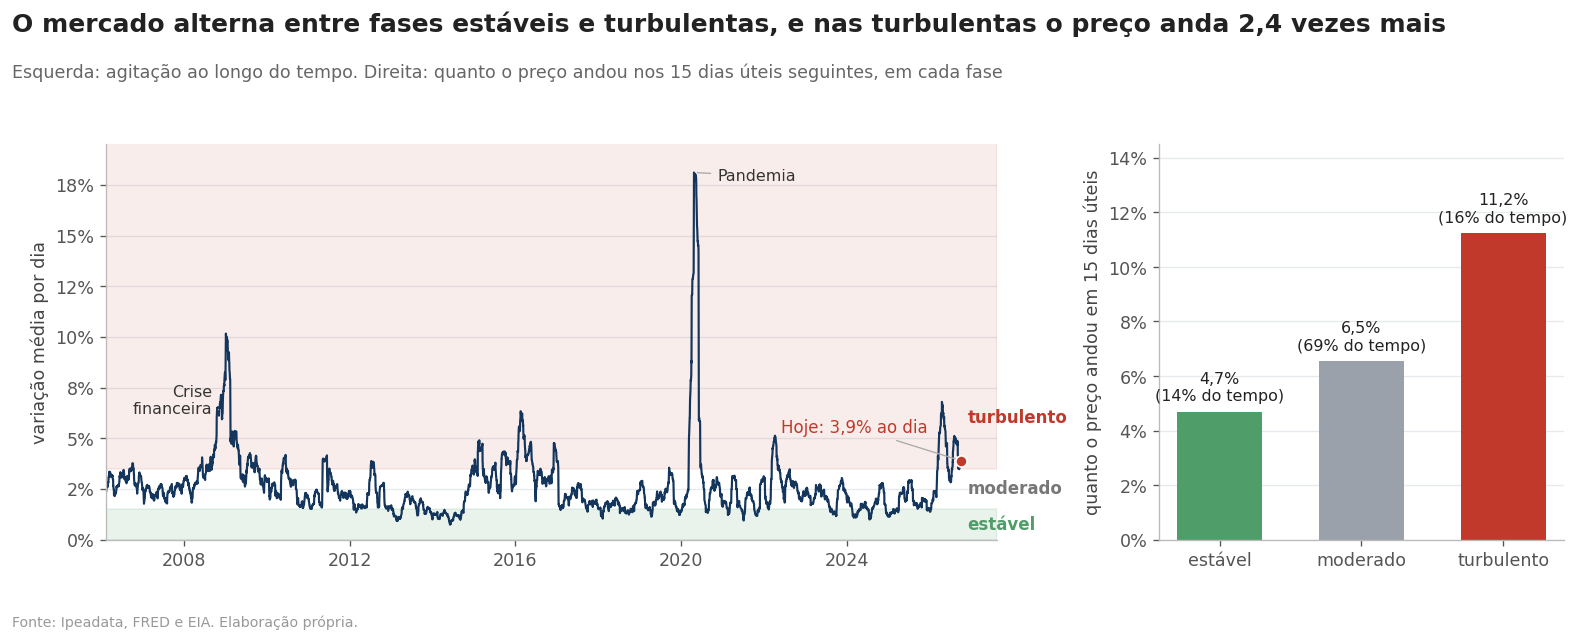

In [6]:
df["agit"] = df["var"].rolling(30).std()                                                                  # agitação: variação média por dia nas últimas 6 semanas (30 dias úteis)
df["mov15"] = (df["preco_usd"].shift(-15) / df["preco_usd"] - 1).abs() * 100                              # quanto o preço andou nos 15 dias úteis seguintes
df["fase"] = pd.cut(df["agit"], [-np.inf, 1.5, 3.5, np.inf], labels=["estável", "moderado", "turbulento"])
t = df.dropna(subset=["agit", "mov15"]).groupby("fase", observed=True).agg(dias=("agit", "size"), mov=("mov15", "mean")); t["tempo"] = t["dias"] / t["dias"].sum() * 100
vezes = t.loc["turbulento", "mov"] / t.loc["estável", "mov"]
fig, axs = moldura((13.5, 5.4), f"O mercado alterna entre fases estáveis e turbulentas, e nas turbulentas o preço anda {br(vezes)} vezes mais", "Esquerda: agitação ao longo do tempo. Direita: quanto o preço andou nos 15 dias úteis seguintes, em cada fase", ncols=2, gridspec_kw={"width_ratios": [2.2, 1]})
ax = axs[0]; ax.axhspan(0, 1.5, color=COR["calmo"], alpha=0.12); ax.axhspan(3.5, 20, color=COR["agitado"], alpha=0.09); ax.plot(D, df["agit"], color=COR["preco"], lw=1.3)
x_fim = D[-1] + pd.Timedelta(days=60)
for yy, txt, cor in [(0.75, "estável", COR["calmo"]), (2.5, "moderado", "#777"), (6, "turbulento", COR["agitado"])]: ax.text(x_fim, yy, txt, fontsize=10, color=cor, fontweight="bold", va="center")
for dt, txt, off in [("2008-12-01", "Crise\nfinanceira", (-6, 6)), ("2020-04-23", "Pandemia", (14, -2))]:
    i = D.get_indexer([pd.Timestamp(dt)], method="nearest")[0]; nota(ax, D[i], df["agit"].iloc[i], txt, off[0], off[1], "left" if off[0] > 0 else "right", size=9.5)
ax.scatter(D[-1], df["agit"].iloc[-1], s=45, color=COR["agitado"], zorder=5, edgecolor="white"); nota(ax, D[-1], df["agit"].iloc[-1], f"Hoje: {br(df['agit'].iloc[-1])}% ao dia", -20, 20, "right", COR["agitado"], size=10)
ax.set_ylim(0, 19.5); ax.set_xlim(D[30], D[-1] + pd.Timedelta(days=320)); pct(ax); ax.set_ylabel("variação média por dia")
ax = axs[1]; cores = [COR["calmo"], "#9aa1aa", COR["agitado"]]
ax.bar(t.index.astype(str), t["mov"], color=cores, width=0.6)
for k, (f, row) in enumerate(t.iterrows()): ax.text(k, row["mov"] + 0.3, f"{br(row['mov'])}%\n({br(row['tempo'], 0)}% do tempo)", ha="center", va="bottom", fontsize=9.5)
pct(ax); ax.set_ylim(0, 14.5); ax.set_ylabel("quanto o preço andou em 15 dias úteis"); plt.show()

### 3.1 A agitação de ontem continua hoje?

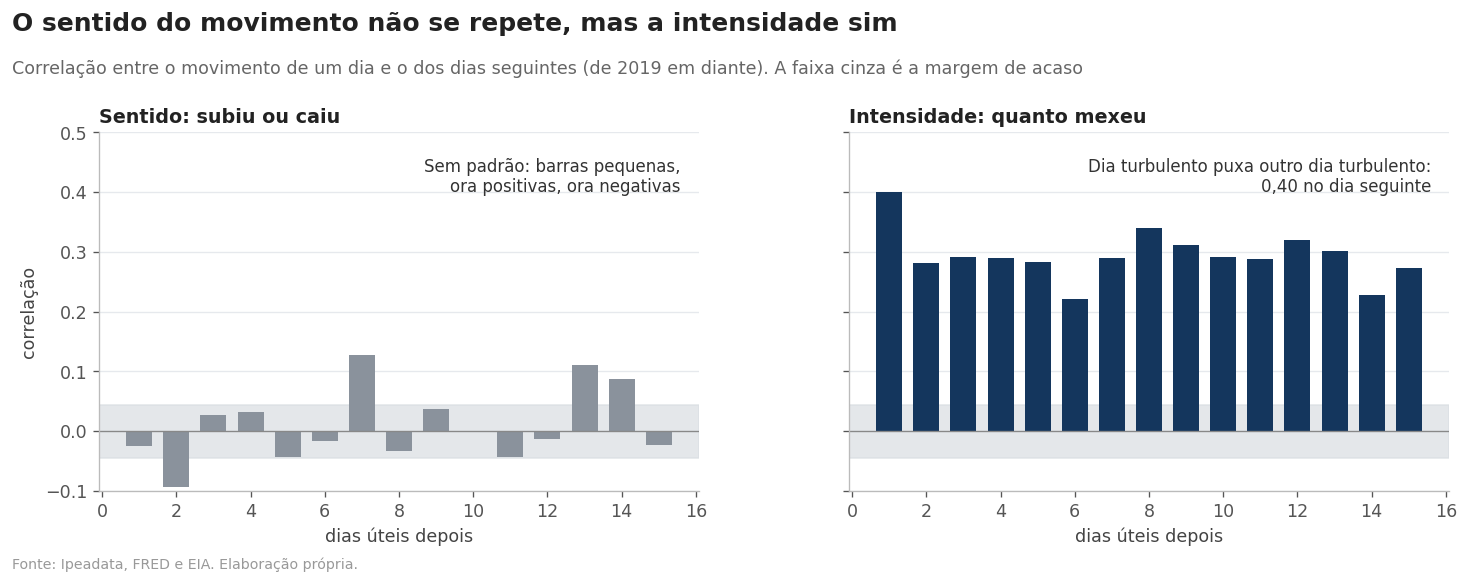

In [7]:
r = df.loc[df["data"] >= "2019-01-01", "var"].dropna().values; banda = 1.96 / np.sqrt(len(r))                         # de 2019 em diante, período com dados diários consistentes
a_dir, a_int = acf(r, nlags=15, fft=True)[1:], acf(np.abs(r), nlags=15, fft=True)[1:]
fig, axs = moldura((12.5, 4.9), "O sentido do movimento não se repete, mas a intensidade sim", "Correlação entre o movimento de um dia e o dos dias seguintes (de 2019 em diante). A faixa cinza é a margem de acaso", ncols=2, sharey=True)
for ax, a, cor, tit, txt in [(axs[0], a_dir, COR["neutro"], "Sentido: subiu ou caiu", "Sem padrão: barras pequenas,\nora positivas, ora negativas"), (axs[1], a_int, COR["preco"], "Intensidade: quanto mexeu", f"Dia turbulento puxa outro dia turbulento:\n{br(a_int[0], 2)} no dia seguinte")]:
    ax.axhspan(-banda, banda, color="#d9dde2", alpha=0.7); ax.bar(range(1, 16), a, color=cor, width=0.7); ax.axhline(0, color="#888", lw=0.8)
    ax.set_title(tit, fontsize=11.5, loc="left", fontweight="bold"); ax.set_xlabel("dias úteis depois"); ax.text(0.97, 0.93, txt, transform=ax.transAxes, ha="right", va="top", fontsize=10, color="#333")
axs[0].set_ylabel("correlação"); axs[0].set_ylim(-0.1, 0.5); plt.show()

**O que vemos**
- O mercado passa a maior parte do tempo em fase **moderada** (69%), com períodos **estáveis** (14%) e **turbulentos** (16%).
- Em fase estável o preço andou em média **4,7%** em 15 dias úteis. Em fase turbulenta, **11,2%**.
- **Hoje o mercado está turbulento**: 3,9% ao dia, contra 2,7% de média.
- A agitação **persiste**: um dia turbulento costuma ser seguido por outro. Já o sentido (subir ou cair) não se repete.

## 4. Dólar e estoques

### 4.1 Dólar

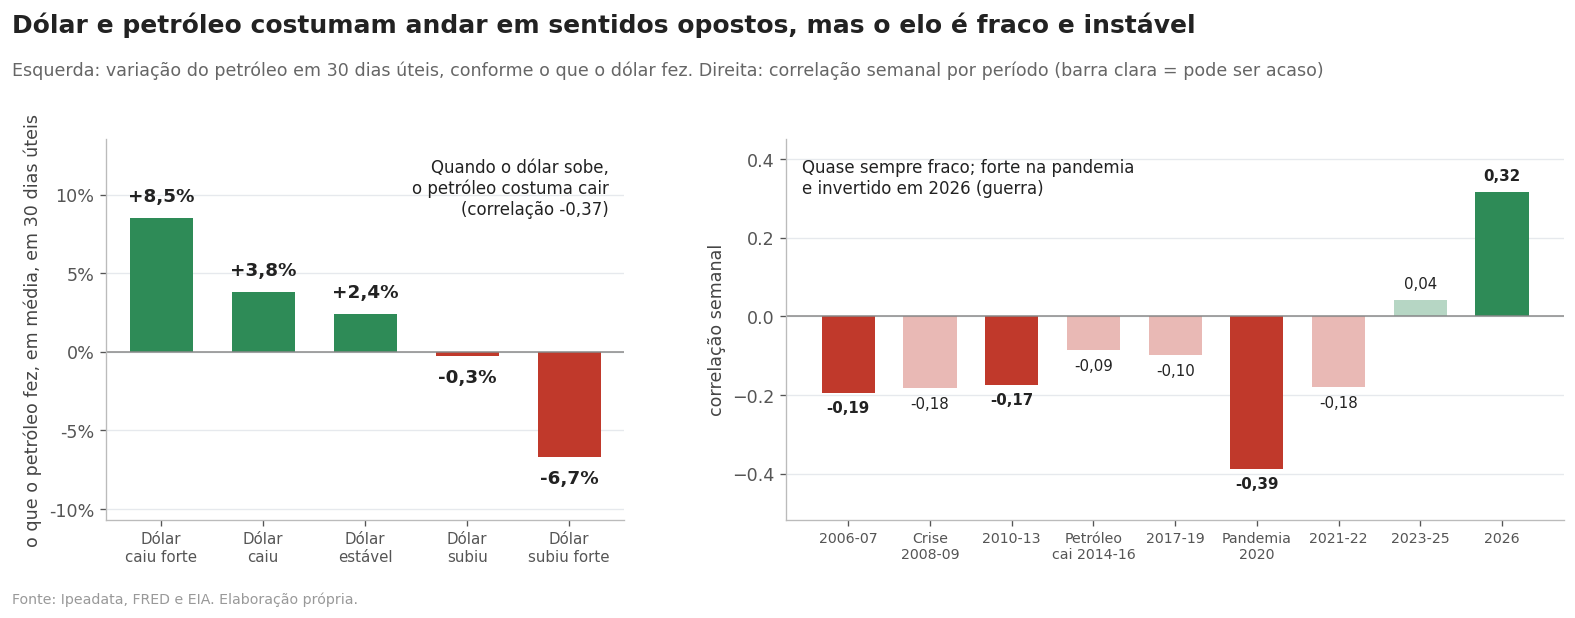

In [8]:
duas = df[["data", "preco_usd"]].merge(dolar.rename(columns={"dolar_amplo": "dolar"}), on="data").set_index("data")
vb, vd = (duas["preco_usd"] / duas["preco_usd"].shift(30) - 1) * 100, (duas["dolar"] / duas["dolar"].shift(30) - 1) * 100
ok = pd.concat([vd, vb], axis=1, keys=["d", "b"]).dropna(); c30 = ok["d"].corr(ok["b"])
sem = duas[["preco_usd", "dolar"]].resample("W-FRI").last().dropna().pct_change().dropna() * 100                          # variação semanal (semanas de calendário, sem sobreposição)
PER = [("2006-07", "2006", "2007"), ("Crise\n2008-09", "2008", "2009"), ("2010-13", "2010", "2013"), ("Petróleo\ncai 2014-16", "2014", "2016"), ("2017-19", "2017", "2019"), ("Pandemia\n2020", "2020", "2020"), ("2021-22", "2021", "2022"), ("2023-25", "2023", "2025"), ("2026", "2026", "2026")]
res = []
for nome, a, b in PER:
    s = sem.loc[a:b]; r_, p_ = stats.pearsonr(s["preco_usd"], s["dolar"]); res.append((nome, r_, p_))
fig, axs = moldura((13.5, 5.2), "Dólar e petróleo costumam andar em sentidos opostos, mas o elo é fraco e instável", "Esquerda: variação do petróleo em 30 dias úteis, conforme o que o dólar fez. Direita: correlação semanal por período (barra clara = pode ser acaso)", ncols=2, gridspec_kw={"width_ratios": [1, 1.5]})
ax = axs[0]
grupo = pd.qcut(ok["d"], 5, labels=["caiu\nforte", "caiu", "ficou\nestável", "subiu", "subiu\nforte"]); g = ok.groupby(grupo, observed=True).agg(oleo=("b", "mean"), dolar=("d", "mean"))
ax.bar(range(5), g["oleo"], color=[COR["alta"] if v > 0 else COR["queda"] for v in g["oleo"]], width=0.62)
for k, (v, dl) in enumerate(zip(g["oleo"], g["dolar"])): ax.text(k, v + (0.8 if v > 0 else -0.8), f"{v:+.1f}%".replace(".", ","), ha="center", va="bottom" if v > 0 else "top", fontsize=11, fontweight="bold")
ax.axhline(0, color="#888", lw=0.9); ax.set_xticks(range(5)); ax.set_xticklabels([f"Dólar\n{t}" for t in ["caiu forte", "caiu", "estável", "subiu", "subiu forte"]], fontsize=9); ax.set_ylim(min(g["oleo"]) - 4, max(g["oleo"]) + 5); pct(ax)
ax.set_ylabel("o que o petróleo fez, em média, em 30 dias úteis"); ax.text(0.97, 0.95, f"Quando o dólar sobe,\no petróleo costuma cair\n(correlação {br(c30, 2)})", transform=ax.transAxes, ha="right", va="top", fontsize=10)
ax = axs[1]
for k, (nome, r_, p_) in enumerate(res):
    ax.bar(k, r_, color=COR["queda"] if r_ < 0 else COR["alta"], alpha=1 if p_ < 0.05 else 0.35, width=0.65); ax.text(k, r_ + (-0.02 if r_ < 0 else 0.02), f"{br(r_, 2)}", ha="center", va="top" if r_ < 0 else "bottom", fontsize=9, fontweight="bold" if p_ < 0.05 else "normal")
ax.axhline(0, color="#888", lw=0.9); ax.set_xticks(range(len(res))); ax.set_xticklabels([n for n, _, _ in res], fontsize=8.5); ax.set_ylim(min(-0.3, min(r for _, r, _ in res) - 0.13), 0.45); ax.set_ylabel("correlação semanal")
ax.text(0.02, 0.95, "Quase sempre fraco; forte na pandemia\ne invertido em 2026 (guerra)", transform=ax.transAxes, ha="left", va="top", fontsize=10); plt.show()

### 4.2 Estoques

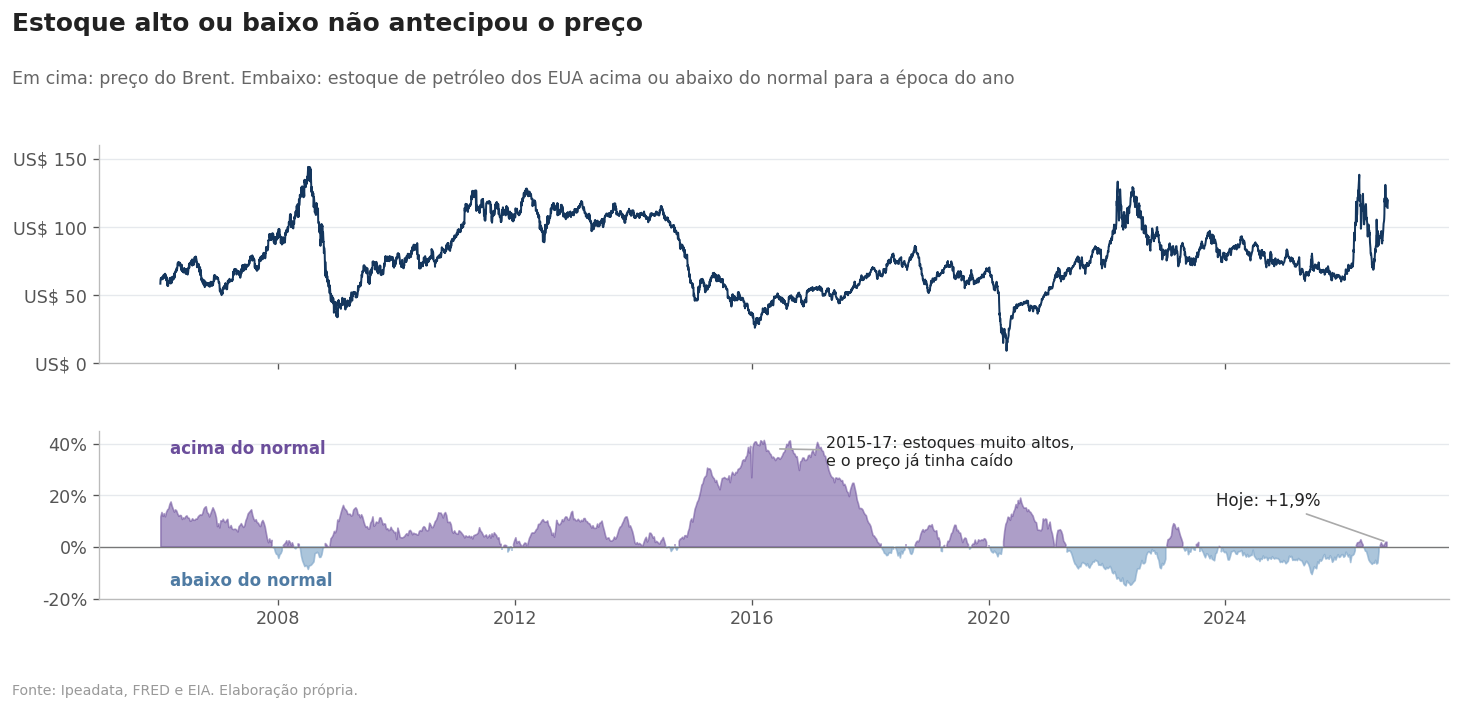

In [9]:
e = est.copy(); e["sem"] = e["semana_ref"].dt.isocalendar().week.astype(int).clip(upper=52); e["ano"] = e["semana_ref"].dt.year
u = e.drop_duplicates(["sem", "ano"], keep="last")[["sem", "ano", "estoque_mil_barris"]].sort_values(["sem", "ano"]).copy()
u["media5"] = u.groupby("sem")["estoque_mil_barris"].transform(lambda s: s.shift(1).rolling(5, min_periods=3).mean())      # média das mesmas semanas dos 5 anos anteriores
e = e.merge(u[["sem", "ano", "media5"]], on=["sem", "ano"], how="left"); e["desvio"] = (e["estoque_mil_barris"] / e["media5"] - 1) * 100; e = e[e["semana_ref"] >= "2006-01-01"].dropna(subset=["desvio"])
fig, axs = moldura((12.5, 6.0), "Estoque alto ou baixo não antecipou o preço", "Em cima: preço do Brent. Embaixo: estoque de petróleo dos EUA acima ou abaixo do normal para a época do ano", nrows=2, sharex=True, topo=0.78, height_ratios=[1.3, 1])
axs[0].plot(D, y, color=COR["preco"], lw=1.2); usd(axs[0]); axs[0].set_ylim(0, 160)
axs[1].fill_between(e["semana_ref"], e["desvio"], 0, where=e["desvio"] > 0, color=COR["estoque"], alpha=0.55); axs[1].fill_between(e["semana_ref"], e["desvio"], 0, where=e["desvio"] <= 0, color="#7fa6c9", alpha=0.65)
axs[1].axhline(0, color="#777", lw=0.8); pct(axs[1]); axs[1].set_ylim(-20, 45)
axs[1].text(e["semana_ref"].iloc[8], 36, "acima do normal", color=COR["estoque"], fontsize=10, fontweight="bold"); axs[1].text(e["semana_ref"].iloc[8], -15, "abaixo do normal", color="#4f7ba3", fontsize=10, fontweight="bold")
axs[1].annotate(f"Hoje: {e['desvio'].iloc[-1]:+.1f}%".replace(".", ","), (e["semana_ref"].iloc[-1], e["desvio"].iloc[-1]), xytext=(-40, 22), textcoords="offset points", ha="right", fontsize=10, arrowprops=dict(arrowstyle="-", color="#aaa"))
axs[1].annotate("2015-17: estoques muito altos,\ne o preço já tinha caído", (pd.Timestamp("2016-06-01"), 38), xytext=(30, -2), textcoords="offset points", fontsize=9.5, va="center", arrowprops=dict(arrowstyle="-", color="#aaa"))
plt.show()

**O que vemos**
- **Dólar:** costuma andar em sentido oposto ao petróleo. Nos 30 dias úteis em que o dólar mais subiu, o petróleo caiu 6,7% em média; quando o dólar mais caiu, o petróleo subiu 8,5%. Mas, semana a semana, o elo é **fraco e instável**: forte na pandemia (−0,39) e **invertido em 2026** (+0,32).
- **Estoques:** hoje estão 1,9% acima do normal para a época. Não há relação clara com o preço dos dias seguintes, e o mercado não reage de forma visível ao dado semanal.

## 5. Amanhã = hoje?

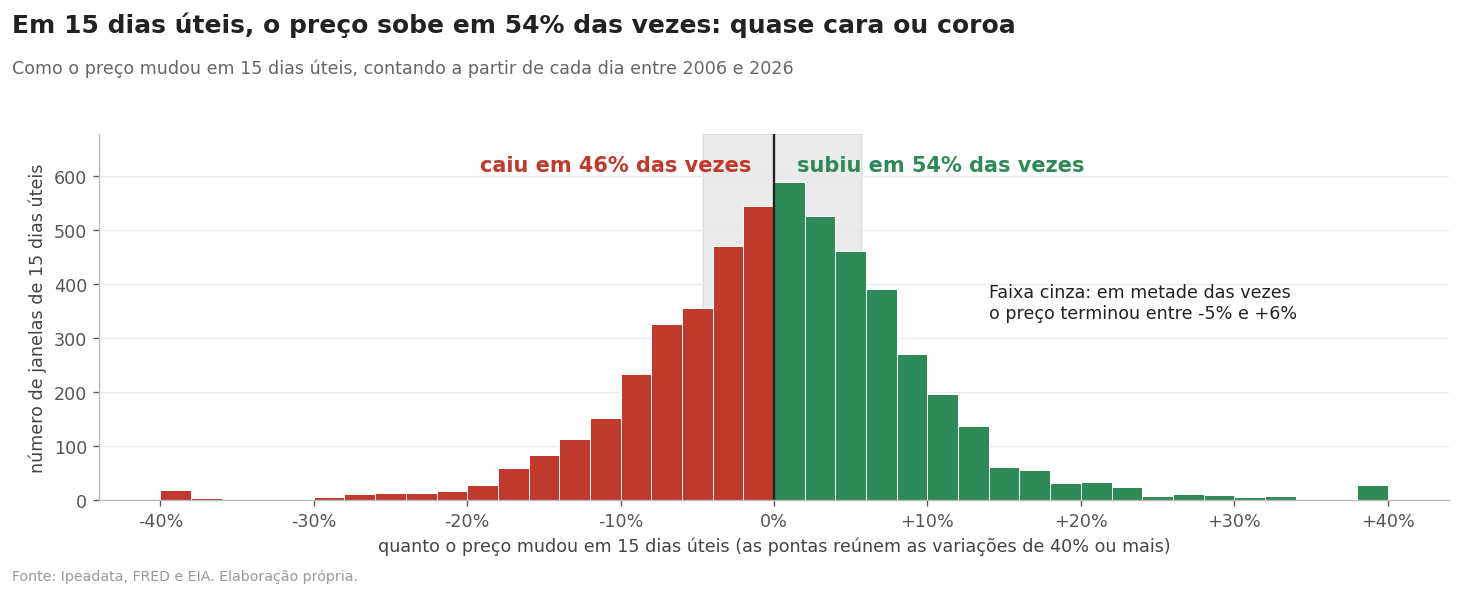

In [10]:
H = 15
mudanca = np.array([(y[t + H] / y[t] - 1) * 100 for t in range(len(y) - H)])                                  # quanto o preço mudou em 15 dias úteis, a partir de cada dia
sobe = (mudanca > 0).mean() * 100; q25, q75 = np.percentile(mudanca, [25, 75])
fig, ax = moldura((12.5, 5.0), f"Em 15 dias úteis, o preço sobe em {br(sobe, 0)}% das vezes: quase cara ou coroa", "Como o preço mudou em 15 dias úteis, contando a partir de cada dia entre 2006 e 2026")
cont, bordas, barras = ax.hist(np.clip(mudanca, -40, 40), bins=np.arange(-40, 41, 2), edgecolor="white", linewidth=0.6)
for barra, esq in zip(barras, bordas[:-1]): barra.set_facecolor(COR["alta"] if esq >= 0 else COR["queda"])
ax.axvline(0, color="#222", lw=1.4); topo = cont.max()
ax.text(-1.5, topo * 1.02, f"caiu em {br(100 - sobe, 0)}% das vezes", ha="right", va="bottom", fontsize=12.5, fontweight="bold", color=COR["queda"])
ax.text(1.5, topo * 1.02, f"subiu em {br(sobe, 0)}% das vezes", ha="left", va="bottom", fontsize=12.5, fontweight="bold", color=COR["alta"])
ax.axvspan(q25, q75, color="#888", alpha=0.16, zorder=0)
ax.text(14, topo * 0.62, f"Faixa cinza: em metade das vezes\no preço terminou entre {q25:+.0f}% e {q75:+.0f}%".replace(".", ","), ha="left", va="center", fontsize=10.5)
ax.set_ylim(0, topo * 1.15); ax.set_xlabel("quanto o preço mudou em 15 dias úteis (as pontas reúnem as variações de 40% ou mais)"); ax.set_ylabel("número de janelas de 15 dias úteis"); ax.grid(axis="x", visible=False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}%" if v != 0 else "0%")); plt.show()

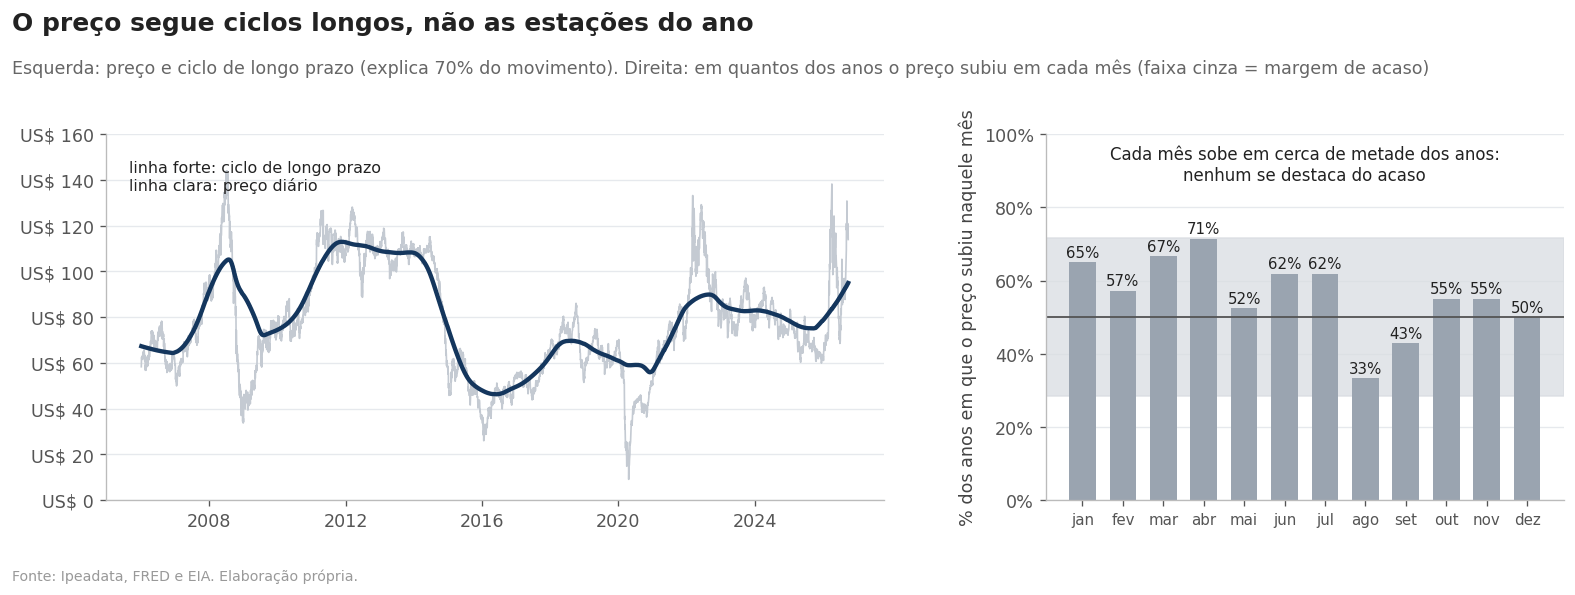

In [11]:
stl = STL(pd.Series(np.log(y), index=D), period=252, robust=True).fit()
f_ciclo = 1 - stl.resid.var() / np.var(stl.trend + stl.resid); f_estacao = 1 - stl.resid.var() / np.var(stl.seasonal + stl.resid)
fig, axs = moldura((13.5, 5.0), "O preço segue ciclos longos, não as estações do ano", f"Esquerda: preço e ciclo de longo prazo (explica {br(f_ciclo * 100, 0)}% do movimento). Direita: em quantos dos anos o preço subiu em cada mês (faixa cinza = margem de acaso)", ncols=2, gridspec_kw={"width_ratios": [1.5, 1]})
ax = axs[0]; ax.plot(D, y, color="#c4cad2", lw=1); ax.plot(D, np.exp(stl.trend), color=COR["preco"], lw=2.6); usd(ax); ax.set_ylim(0, 160)
ax.text(0.03, 0.93, "linha forte: ciclo de longo prazo\nlinha clara: preço diário", transform=ax.transAxes, va="top", fontsize=9.5)
mensal = df.set_index("data")["preco_usd"].resample("ME").last().pct_change().dropna() * 100                     # quanto o preço mudou em cada mês
mm = mensal.groupby(mensal.index.month).agg(sobe=lambda s_: (s_ > 0).mean() * 100, anos="size"); marg = 1.96 * np.sqrt(0.25 / mm["anos"].mean()) * 100
ax = axs[1]; meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
ax.axhspan(50 - marg, 50 + marg, color="#d9dde2", alpha=0.75); ax.axhline(50, color="#555", lw=1.1)
ax.bar(meses, mm["sobe"], color=[COR["destaque"] if abs(v - 50) > marg else "#9aa4b0" for v in mm["sobe"]], width=0.66)
for k, v in enumerate(mm["sobe"]): ax.text(k, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9)
fora = int((abs(mm["sobe"] - 50) > marg).sum()); ax.set_ylim(0, 100); pct(ax); ax.set_ylabel("% dos anos em que o preço subiu naquele mês"); ax.tick_params(axis="x", labelsize=9)
ax.text(0.5, 0.97, f"Cada mês sobe em cerca de metade dos anos:\n{'nenhum se destaca do acaso' if fora == 0 else str(fora) + ' se destacam'}", transform=ax.transAxes, ha="center", va="top", fontsize=10)
plt.show()

**O que vemos**
- Em 15 dias úteis o preço **sobe em 54% das vezes**: sem vantagem clara para nenhum lado. Em metade das vezes ele termina entre −5% e +6% de onde começou.
- O movimento do preço é de **ciclos longos** (70%). O calendário (mês, estação do ano) explica quase nada (2%).

## 6. O que levamos para a modelagem

| O que os dados mostram | O que isso significa |
|---|---|
| Direção quase aleatória e sem calendário (sobe em 54% das vezes) | **"Amanhã = hoje"** é uma boa âncora para o preço. Ela serve para explicar o resto, não para ser batida |
| O mercado alterna fases estáveis e turbulentas, e a agitação **persiste** | A **agitação é previsível** e é onde a modelagem pode agregar |
| Em fase turbulenta o preço anda mais que o dobro | A agitação prevista vira o **tamanho da faixa** de preços |
| Dólar e estoques ajudam pouco | Entram como contexto, sem esperar muito deles |

---
# Parte 2: Modelagem

## 7. Preparando a modelagem

O que vamos prever, em três perguntas simples:
1. **Quão agitado o mercado vai estar** nos próximos 15 dias úteis? (e em qual fase: estável, moderado ou turbulento)
2. **Entre quais preços** ele deve ficar? (o preço de hoje é a âncora, e a agitação define o tamanho da faixa)
3. **O preço vai subir ou cair?**

O modelo recebe, **em cada dia**, só o que já se sabia naquele dia: o movimento recente do preço, o dólar, os estoques e o calendário.

Teste de vazamento: 25 datas conferidas, nenhuma feature enxerga o futuro.


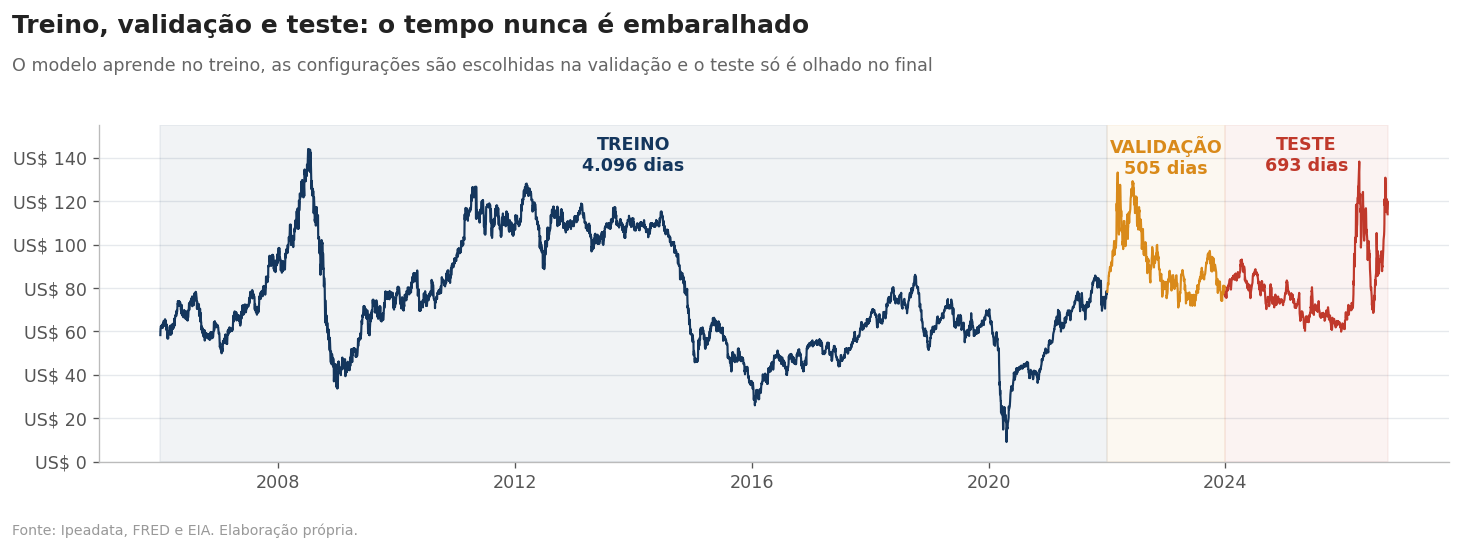

In [12]:
import json, time
import lightgbm as lgb, optuna
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEMENTE, N_JOBS, H, REFIT = 42, 6, 15, 63
ART = BASE.parent / "01_Notebook" / "artefatos"; ART.mkdir(exist_ok=True)

def construir_features(base_d, est_w):
    """features de cada dia, usando só informação disponível até o próprio dia"""
    d = base_d.sort_values("data").reset_index(drop=True); p = d["preco_usd"]; r = p.pct_change() * 100; F = pd.DataFrame({"data": d["data"]})
    F["brent_preco"] = p; F["brent_var_1d"], F["brent_var_7d"], F["brent_var_30d"] = r, p.pct_change(7) * 100, p.pct_change(30) * 100
    F["brent_media_7d"], F["brent_media_30d"], F["brent_desv_pad_30d"] = p.rolling(7).mean(), p.rolling(30).mean(), r.rolling(30).std()
    s = d["dolar_d1"]; rs = s.pct_change() * 100
    F["dolar_d1"], F["dolar_var_1d"], F["dolar_var_7d"] = s, rs, s.pct_change(7) * 100; F["dolar_media_30d"], F["dolar_desv_pad_30d"] = s.rolling(30).mean(), rs.rolling(30).std()
    e = est_w.sort_values("semana_ref").reset_index(drop=True).copy(); e["sem"] = e["semana_ref"].dt.isocalendar().week.astype(int).clip(upper=52); e["ano"] = e["semana_ref"].dt.year
    u = e.drop_duplicates(["sem", "ano"], keep="last")[["sem", "ano", "estoque_mil_barris"]].sort_values(["sem", "ano"]).copy()
    u["media_5a"] = u.groupby("sem")["estoque_mil_barris"].transform(lambda x: x.shift(1).rolling(5, min_periods=3).mean()); e = e.merge(u[["sem", "ano", "media_5a"]], on=["sem", "ano"], how="left")
    E = pd.DataFrame({"data_disponivel": e["data_disponivel"], "est_nivel": e["estoque_mil_barris"].astype(float), "est_var_1s": e["estoque_mil_barris"].pct_change() * 100,
                      "est_var_4s": e["estoque_mil_barris"].pct_change(4) * 100, "est_media_4s": e["estoque_mil_barris"].rolling(4).mean(), "est_media_5a": e["media_5a"]}); E["est_desvio_pct"] = (E["est_nivel"] / E["est_media_5a"] - 1) * 100
    F = pd.merge_asof(F, E.sort_values("data_disponivel"), left_on="data", right_on="data_disponivel", direction="backward").drop(columns="data_disponivel")
    F["cal_mes"], F["cal_trimestre"], F["cal_dia_semana"] = F["data"].dt.month, F["data"].dt.quarter, F["data"].dt.dayofweek; F["cal_semana_ano"] = F["data"].dt.isocalendar().week.astype(int).clip(upper=52).values
    F["rel_brent_vs_media7"], F["rel_brent_vs_media30"] = (F["brent_preco"] / F["brent_media_7d"] - 1) * 100, (F["brent_preco"] / F["brent_media_30d"] - 1) * 100
    F["rel_dolar_vs_media30"], F["rel_est_vs_media4s"] = (F["dolar_d1"] / F["dolar_media_30d"] - 1) * 100, (F["est_nivel"] / F["est_media_4s"] - 1) * 100
    return F

FEAT = ["brent_var_1d", "brent_var_7d", "brent_var_30d", "brent_desv_pad_30d", "rel_brent_vs_media7", "rel_brent_vs_media30", "dolar_var_1d", "dolar_var_7d", "dolar_desv_pad_30d", "rel_dolar_vs_media30",
        "est_var_1s", "est_var_4s", "est_desvio_pct", "rel_est_vs_media4s", "cal_mes", "cal_trimestre", "cal_semana_ano", "cal_dia_semana"]
NOMES = {"brent_var_1d": "Variação de ontem", "brent_var_7d": "Variação em 7 dias", "brent_var_30d": "Variação em 30 dias", "brent_desv_pad_30d": "Agitação das últimas 6 semanas", "rel_brent_vs_media7": "Preço vs média de 7 dias",
         "rel_brent_vs_media30": "Preço vs média de 30 dias", "dolar_var_1d": "Dólar: variação de ontem", "dolar_var_7d": "Dólar: variação em 7 dias", "dolar_desv_pad_30d": "Dólar: agitação", "rel_dolar_vs_media30": "Dólar vs média de 30 dias",
         "est_var_1s": "Estoque: variação na semana", "est_var_4s": "Estoque: variação em 4 semanas", "est_desvio_pct": "Estoque vs normal da época", "rel_est_vs_media4s": "Estoque vs média de 4 semanas",
         "cal_mes": "Mês", "cal_trimestre": "Trimestre", "cal_semana_ano": "Semana do ano", "cal_dia_semana": "Dia da semana"}
GRUPO = {f: ("Brent" if f.startswith(("brent", "rel_brent")) else "Dólar" if f.startswith(("dolar", "rel_dolar")) else "Estoques" if f.startswith(("est", "rel_est")) else "Calendário") for f in FEAT}
CORG = {"Brent": COR["preco"], "Dólar": COR["dolar"], "Estoques": COR["estoque"], "Calendário": COR["neutro"]}

DS = construir_features(base, est); INI = int(np.argmax(DS[FEAT].notna().all(axis=1).values))
DS["agit15"] = np.log(DS["brent_var_1d"].rolling(15).std().shift(-15))                                         # alvo 1: agitação dos próximos 15 dias úteis (em log)
for h in (1, 5, 10, 15): DS[f"var_{h}"] = np.log(DS["brent_preco"].shift(-h) / DS["brent_preco"]) * 100         # variação do preço daqui a h dias úteis
PRECO, DATAS = DS["brent_preco"].values, DS["data"].values; X = DS[FEAT].values.astype(float)

# teste de vazamento: recalcular as features só com dados até cada data dá exatamente o mesmo resultado
rng = np.random.default_rng(SEMENTE); cols = [c for c in DS.columns if c not in ("data", "agit15") and not c.startswith("var_")]
for i in rng.choice(np.arange(INI + 5, len(DS) - 20), size=25, replace=False):
    t = DS.loc[i, "data"]; Ft = construir_features(base[base["data"] <= t], est[est["data_disponivel"] <= t])
    assert Ft.iloc[-1]["data"] == t and np.allclose(Ft.iloc[-1][cols].astype(float).values, DS.loc[i, cols].astype(float).values, equal_nan=True), f"vazamento em {t}"
print("Teste de vazamento: 25 datas conferidas, nenhuma feature enxerga o futuro.")

T_FIM, V_INI, V_FIM, TE_INI, FIM = pd.Timestamp("2021-12-31"), pd.Timestamp("2022-01-01"), pd.Timestamp("2023-12-31"), pd.Timestamp("2024-01-01"), DS["data"].max()
PER = {"validação": (V_INI, V_FIM), "teste": (TE_INI, FIM)}
periodo = np.select([DS["data"] <= T_FIM, DS["data"] <= V_FIM], ["treino", "validação"], "teste")
fig, ax = moldura((12.5, 4.6), "Treino, validação e teste: o tempo nunca é embaralhado", "O modelo aprende no treino, as configurações são escolhidas na validação e o teste só é olhado no final")
for nome, cor in [("treino", COR["preco"]), ("validação", COR["dolar"]), ("teste", COR["queda"])]:
    m = periodo == nome; ax.plot(DS["data"][m], DS["brent_preco"][m], color=cor, lw=1.3); ax.axvspan(DS["data"][m].min(), DS["data"][m].max(), color=cor, alpha=0.06)
    ax.text(DS["data"][m].min() + (DS["data"][m].max() - DS["data"][m].min()) / 2, 150, f"{nome.upper()}\n{int((m & (np.arange(len(DS)) >= INI)).sum()):,} dias".replace(",", "."), ha="center", va="top", fontsize=10.5, fontweight="bold", color=cor)
usd(ax); ax.set_ylim(0, 155); plt.show()

def origens(a, b, h): return np.where(((DS["data"] >= a) & (DS["data"] <= b) & (DS.index >= INI) & (DS.index + h < len(DS))).values)[0]
def walk_forward(fit_predict, a, b, h, refit=REFIT):
    """a cada 63 dias úteis o modelo é treinado de novo, só com amostras cujo resultado já aconteceu; devolve a previsão de cada dia do período"""
    idx = origens(a, b, h); out = []
    for k in range(0, len(idx), refit):
        blk = idx[k:k + refit]; tr = np.arange(INI, blk[0] - h + 1); assert tr[-1] + h <= blk[0], "treino invade o futuro"; out.append(pd.Series(fit_predict(tr, blk), index=blk))
    return pd.concat(out)

**Como o modelo é testado:** a cada 63 dias úteis (cerca de 3 meses) ele é treinado de novo e prevê os dias seguintes sem ver o futuro, como aconteceria na vida real. A divisão é **treino de 2006 a 2021**, **validação em 2022 e 2023** e **teste de 2024 a set/2026**.

## 8. Modelo 1: quão agitado o mercado vai estar?

Um **LightGBM** prevê a agitação dos próximos 15 dias úteis (o quanto o preço deve mexer por dia). Ele **parte da agitação de hoje e aprende a correção**: em que situações ela costuma subir ou cair. Usa só **variações e comparações** (nunca o nível do preço), para não decorar épocas. Os parâmetros são escolhidos pelo **Optuna**, só na validação.

**Contra quem ele compete:** "a agitação de hoje continua" (repetir a agitação das últimas 6 semanas). Pela EDA essa regra já é forte, e o modelo só vale se acrescentar algo a ela.

In [13]:
Y_AG = DS["agit15"].values; BASE_LOG = np.log(DS["brent_desv_pad_30d"].values); Y_DELTA = Y_AG - BASE_LOG; X_REL = X          # o modelo aprende a correção sobre "a agitação de hoje continua"
def lgbm_agit(params):
    def f(tr, pr):
        m = lgb.LGBMRegressor(**params, random_state=SEMENTE, verbose=-1, n_jobs=N_JOBS); m.fit(X_REL[tr], Y_DELTA[tr]); return BASE_LOG[pr] + m.predict(X_REL[pr])
    return f
def par_reg(trial):
    return dict(objective="regression", n_estimators=trial.suggest_int("n_estimators", 40, 400), learning_rate=trial.suggest_float("learning_rate", 0.005, 0.1, log=True), num_leaves=trial.suggest_int("num_leaves", 3, 15),
                max_depth=trial.suggest_int("max_depth", 2, 5), min_child_samples=trial.suggest_int("min_child_samples", 30, 300), subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
                colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0), reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True), reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 50, log=True))
arq = ART / "agitacao_corrigida.json"
if arq.exists(): P_AG = json.loads(arq.read_text(encoding="utf-8"))["params"]
else:
    def obj(trial):
        pr = walk_forward(lgbm_agit(par_reg(trial)), V_INI, V_FIM, H, refit=126); return float(np.abs(pr.values - Y_AG[pr.index]).mean())
    st = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEMENTE)); st.optimize(obj, n_trials=40)
    P_AG = par_reg(optuna.trial.FixedTrial(st.best_params)); arq.write_text(json.dumps({"params": P_AG, "erro_validacao": st.best_value}, indent=1), encoding="utf-8")

FASE = lambda v: pd.cut(np.exp(v), [0, 1.5, 3.5, np.inf], labels=["estável", "moderado", "turbulento"]).astype(str)
AG = {}
for per, (a, b) in PER.items():
    pr = walk_forward(lgbm_agit(P_AG), a, b, H); i = pr.index.values
    AG[per] = dict(i=i, real=Y_AG[i], modelo=pr.values, hoje=np.log(DS["brent_desv_pad_30d"].values[i]), data=DATAS[i])
linhas = []
for per in PER:
    d = AG[per]; fr = FASE(d["real"])
    linhas.append({"Período": per, "Erro típico do modelo": np.exp(np.abs(d["modelo"] - d["real"]).mean()) - 1, "Erro típico de 'a agitação de hoje continua'": np.exp(np.abs(d["hoje"] - d["real"]).mean()) - 1,
                   "Acerta a fase (modelo)": (FASE(d["modelo"]) == fr).mean() * 100, "Acerta a fase ('hoje continua')": (FASE(d["hoje"]) == fr).mean() * 100, "Acerta a fase (sempre 'moderado')": (fr == "moderado").mean() * 100})
TAB_AG = pd.DataFrame(linhas)
display(TAB_AG.style.hide(axis="index").format({c: "{:.0%}" for c in TAB_AG.columns if "Erro" in c} | {c: "{:.0f}%" for c in TAB_AG.columns if "Acerta" in c}))

Período,Erro típico do modelo,Erro típico de 'a agitação de hoje continua',Acerta a fase (modelo),Acerta a fase ('hoje continua'),Acerta a fase (sempre 'moderado')
validação,29%,32%,77%,80%,79%
teste,37%,38%,56%,59%,56%


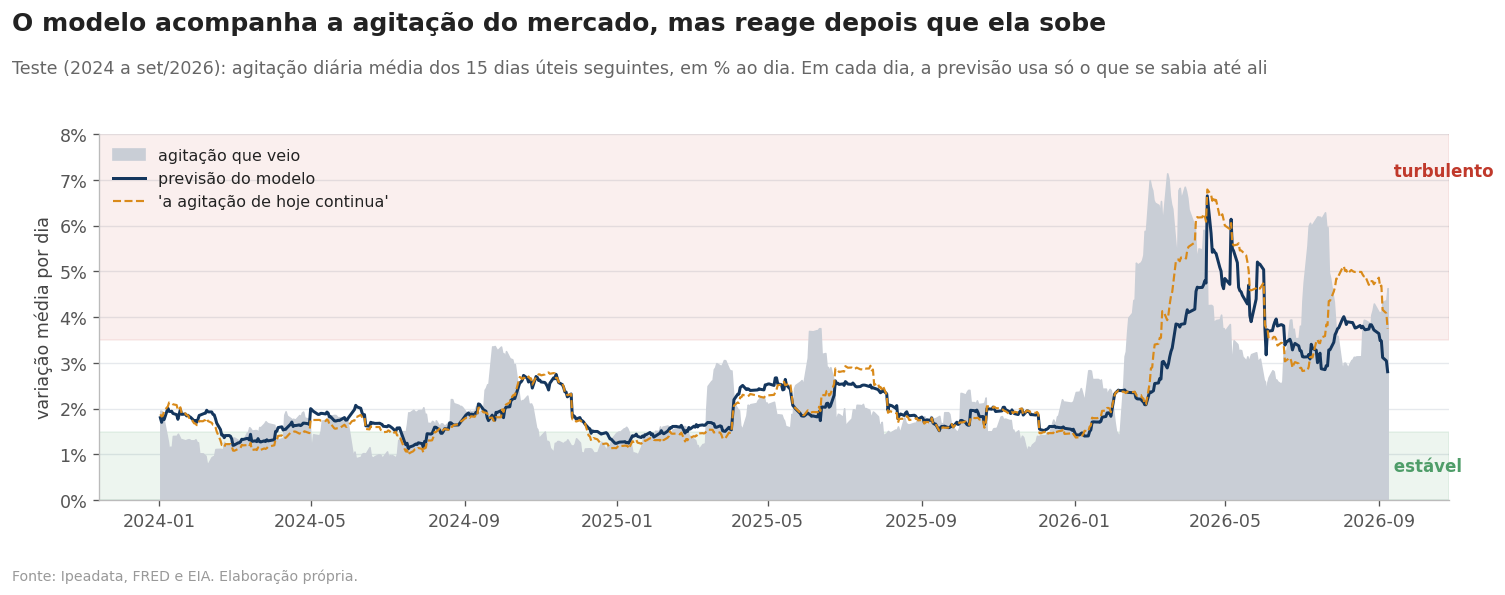

In [14]:
d = AG["teste"]; dt = pd.to_datetime(d["data"])
fig, ax = moldura((12.5, 5.0), "O modelo acompanha a agitação do mercado, mas reage depois que ela sobe", "Teste (2024 a set/2026): agitação diária média dos 15 dias úteis seguintes, em % ao dia. Em cada dia, a previsão usa só o que se sabia até ali")
ax.axhspan(0, 1.5, color=COR["calmo"], alpha=0.10); ax.axhspan(3.5, 12, color=COR["agitado"], alpha=0.08)
ax.fill_between(dt, np.exp(d["real"]), color="#c9ced6", label="agitação que veio"); ax.plot(dt, np.exp(d["modelo"]), color=COR["preco"], lw=1.8, label="previsão do modelo"); ax.plot(dt, np.exp(d["hoje"]), color=COR["dolar"], lw=1.3, ls="--", label="'a agitação de hoje continua'")
ax.set_ylim(0, 8); pct(ax); ax.set_ylabel("variação média por dia"); ax.legend(loc="upper left", fontsize=9.5)
for yy, txt, cor in [(0.75, "estável", COR["calmo"]), (7.2, "turbulento", COR["agitado"])]: ax.text(dt.max(), yy, " " + txt, fontsize=10, color=cor, fontweight="bold", va="center")
plt.show()

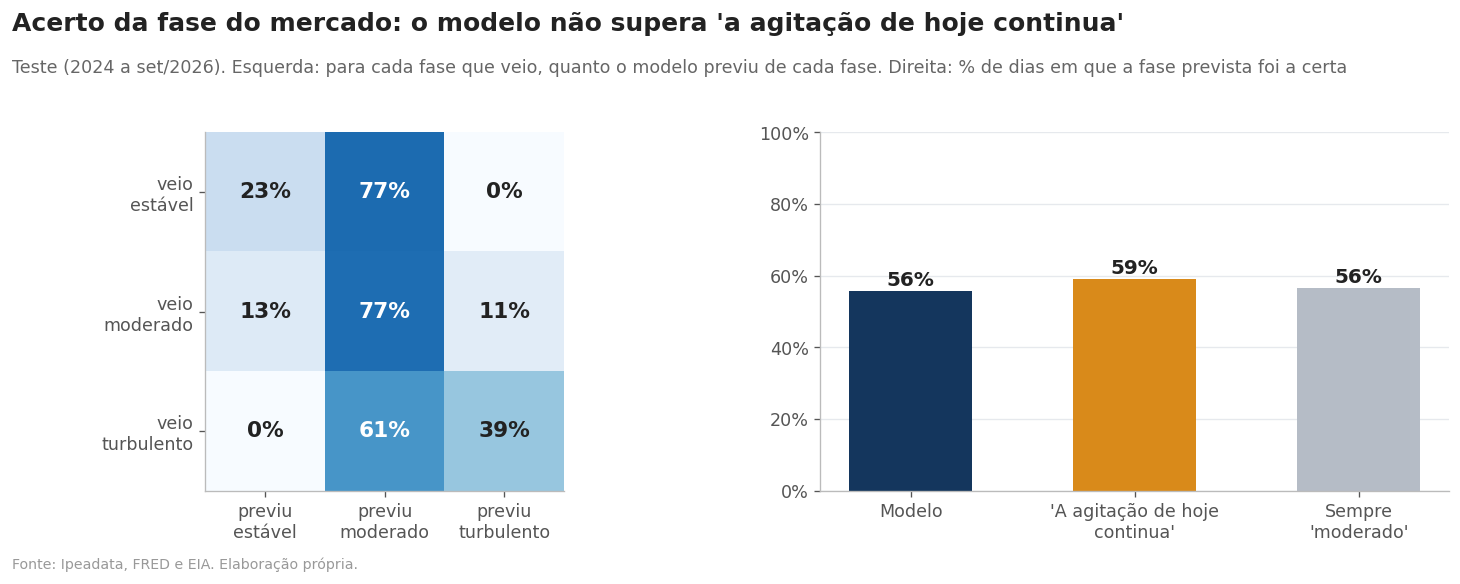

In [15]:
FS = ["estável", "moderado", "turbulento"]; d = AG["teste"]; fr, fm = FASE(d["real"]), FASE(d["modelo"])
M = np.array([[np.mean(fm[fr == i] == j) * 100 if (fr == i).any() else np.nan for j in FS] for i in FS])
fig, axs = moldura((12.5, 4.9), "Acerto da fase do mercado: o modelo não supera 'a agitação de hoje continua'", "Teste (2024 a set/2026). Esquerda: para cada fase que veio, quanto o modelo previu de cada fase. Direita: % de dias em que a fase prevista foi a certa", ncols=2, gridspec_kw={"width_ratios": [1, 1.1]})
ax = axs[0]; ax.imshow(np.nan_to_num(M), cmap="Blues", vmin=0, vmax=100); ax.grid(False)
for i in range(3):
    for j in range(3): ax.text(j, i, f"{M[i, j]:.0f}%" if not np.isnan(M[i, j]) else "—", ha="center", va="center", fontsize=13, fontweight="bold", color="white" if M[i, j] > 55 else "#222")
ax.set_xticks(range(3)); ax.set_xticklabels([f"previu\n{f}" for f in FS]); ax.set_yticks(range(3)); ax.set_yticklabels([f"veio\n{f}" for f in FS])
ax = axs[1]; rot = ["Modelo", "'A agitação de hoje\ncontinua'", "Sempre\n'moderado'"]; val = [TAB_AG.loc[1, "Acerta a fase (modelo)"], TAB_AG.loc[1, "Acerta a fase ('hoje continua')"], TAB_AG.loc[1, "Acerta a fase (sempre 'moderado')"]]
ax.bar(rot, val, color=[COR["preco"], COR["dolar"], "#b5bcc6"], width=0.55)
for k, v in enumerate(val): ax.text(k, v + 1.5, f"{v:.0f}%", ha="center", fontsize=12, fontweight="bold")
ax.set_ylim(0, 100); pct(ax); plt.show()

**O que vemos (teste)**
- A agitação prevista segue a que de fato veio, mas **reage depois**: nos saltos de 2026 a previsão só sobe depois que a agitação já subiu.
- O modelo erra em média **37%**, contra **38%** de "a agitação de hoje continua": o ganho é **pequeno**. Na fase do mercado acerta **56%** dos dias, contra 59% da âncora e 56% de dizer sempre "moderado".
- Ele reconhece parte das fases extremas (23% dos dias estáveis e 39% dos turbulentos), mas ainda confunde muitos deles com "moderado".

## 9. Entre quais preços ele deve ficar?

O preço de hoje é a **âncora**. A agitação prevista define o **tamanho da faixa**:

`faixa = preço de hoje ± agitação prevista × √(dias úteis) × fator`

O **fator** é calibrado na validação para que a faixa de 80% cubra 80% dos casos. A faixa pode vir da previsão do modelo ou da regra "a agitação de hoje continua". Escolhemos pela **menor erro na validação**.

In [16]:
for h in (5, 10, 15): pass
ESC = "modelo" if np.abs(AG["validação"]["modelo"] - AG["validação"]["real"]).mean() <= np.abs(AG["validação"]["hoje"] - AG["validação"]["real"]).mean() else "hoje"
NOME_ESC = {"modelo": "previsão do modelo", "hoje": "agitação de hoje"}[ESC]
def pontos(per, fonte, hs=(5, 10, 15)):
    d = AG[per]; sg = np.exp(d[fonte]); L = []
    for h in hs:
        v = DS[f"var_{h}"].values[d["i"]] if h != 5 and h != 10 else DS[f"var_{h}"].values[d["i"]]
        ok = ~np.isnan(v); L.append(pd.DataFrame({"i": d["i"][ok], "h": h, "var": v[ok], "sig": sg[ok], "vol": DS["brent_desv_pad_30d"].values[d["i"][ok]]}))
    R = pd.concat(L, ignore_index=True); R["z"] = R["var"] / (R["sig"] * np.sqrt(R["h"])); return R
FONTE = "modelo" if ESC == "modelo" else "hoje"
RV, RT = pontos("validação", FONTE), pontos("teste", FONTE); RVh, RTh = pontos("validação", "hoje"), pontos("teste", "hoje")
Q80 = np.quantile(RV["z"], [0.10, 0.90]); Q95 = np.quantile(RV["z"], [0.025, 0.975]); Q80h = np.quantile(RVh["z"], [0.10, 0.90])
def cobre(R, q): return (R["z"] >= q[0]) & (R["z"] <= q[1])
fase_t = pd.cut(RT["vol"], [-np.inf, 1.5, 3.5, np.inf], labels=FS).astype(str); r15 = RT["h"] == 15
fixa = {h: np.quantile(RV.loc[RV["h"] == h, "var"], [0.10, 0.90]) for h in (5, 10, 15)}
dentro_fixa = (RT["var"] >= RT["h"].map(lambda h: fixa[h][0])) & (RT["var"] <= RT["h"].map(lambda h: fixa[h][1]))
dentro = cobre(RT, Q80)
COB = pd.DataFrame({"Faixa": ["fixa (sem olhar a agitação)", f"pela agitação ({NOME_ESC})"], **{f: [dentro_fixa[r15 & (fase_t == f)].mean() * 100, dentro[r15 & (fase_t == f)].mean() * 100] for f in FS}, "Todos os dias": [dentro_fixa[r15].mean() * 100, dentro[r15].mean() * 100]})
display(COB.style.hide(axis="index").format({c: "{:.0f}%" for c in COB.columns if c != "Faixa"}))
print(f"Forma escolhida: {NOME_ESC}. Quantis do fator (80%): {Q80.round(2)}. Cobertura em 15 dias úteis no teste; a meta é 80%.")

Faixa,estável,moderado,turbulento,Todos os dias
fixa (sem olhar a agitação),91%,85%,44%,81%
pela agitação (previsão do modelo),66%,81%,73%,76%


Forma escolhida: previsão do modelo. Quantis do fator (80%): [-1.26  1.22]. Cobertura em 15 dias úteis no teste; a meta é 80%.


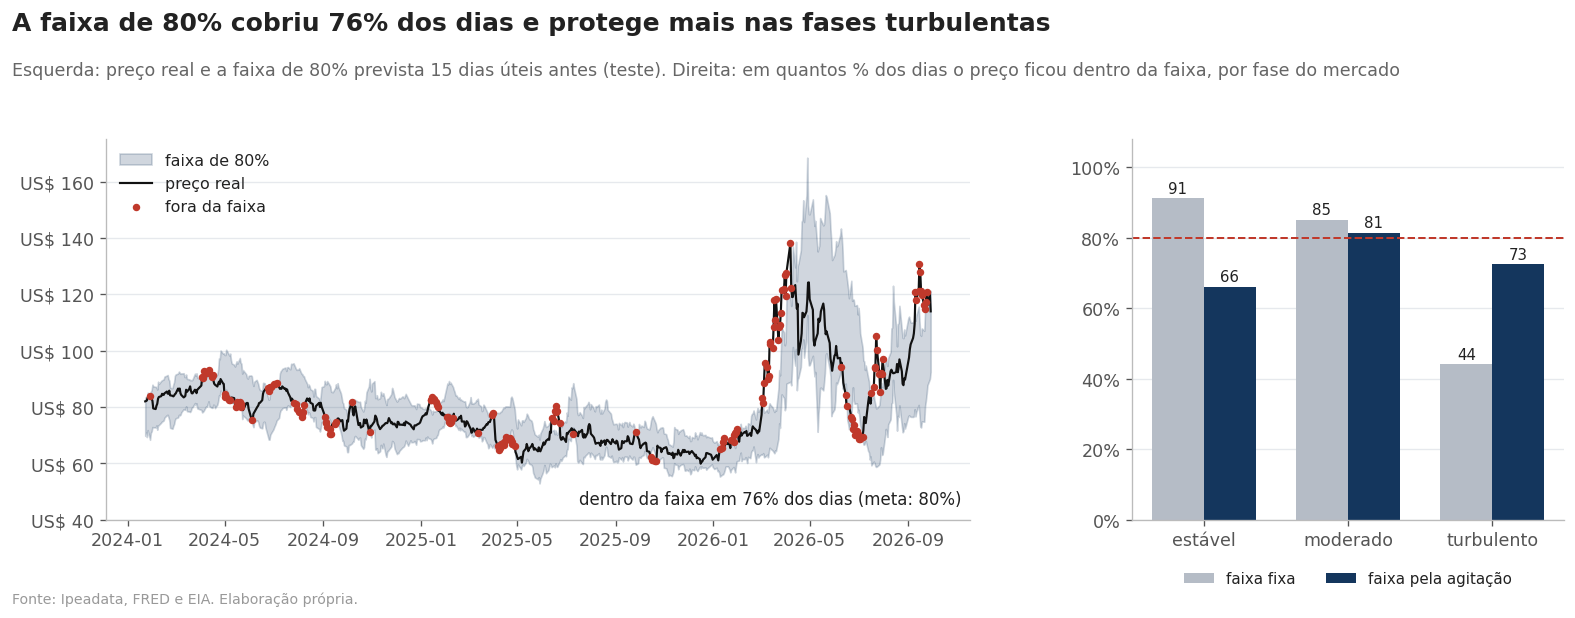

In [17]:
# backtest em 15 dias úteis no teste: a faixa prevista no dia t, desenhada na data t+15, contra o preço que de fato veio
d = AG["teste"]; i = d["i"][~np.isnan(DS["var_15"].values[d["i"]])]; sg = pd.Series(np.exp(d[FONTE]), index=d["i"]).loc[i].values
p0 = PRECO[i]; lo, hi = p0 * np.exp(Q80[0] * sg * np.sqrt(15) / 100), p0 * np.exp(Q80[1] * sg * np.sqrt(15) / 100); alvo = pd.to_datetime(DATAS[i + 15]); real = PRECO[i + 15]; fora = (real < lo) | (real > hi)
fig, axs = moldura((13.5, 5.2), f"A faixa de 80% cobriu {(~fora).mean() * 100:.0f}% dos dias e protege mais nas fases turbulentas", "Esquerda: preço real e a faixa de 80% prevista 15 dias úteis antes (teste). Direita: em quantos % dos dias o preço ficou dentro da faixa, por fase do mercado", ncols=2, gridspec_kw={"width_ratios": [2, 1]})
ax = axs[0]; ax.fill_between(alvo, lo, hi, color=COR["preco"], alpha=0.20, label="faixa de 80%"); ax.plot(alvo, real, color="#111", lw=1.3, label="preço real"); ax.scatter(alvo[fora], real[fora], s=12, color=COR["queda"], zorder=5, label="fora da faixa")
usd(ax); ax.set_ylim(40, 175); ax.legend(loc="upper left", fontsize=9.5); ax.text(0.99, 0.04, f"dentro da faixa em {(~fora).mean() * 100:.0f}% dos dias (meta: 80%)", transform=ax.transAxes, ha="right", fontsize=10)
ax = axs[1]; w = 0.36
for j, (lin, cor, nome) in enumerate([(0, "#b5bcc6", "faixa fixa"), (1, COR["preco"], "faixa pela agitação")]):
    v = [COB.loc[lin, f] for f in FS]; ax.bar(np.arange(3) + (j - 0.5) * w, v, width=w, color=cor, label=nome)
    for xx, vv in zip(np.arange(3) + (j - 0.5) * w, v): ax.text(xx, vv + 1.5, f"{vv:.0f}", ha="center", fontsize=9)
ax.axhline(80, color=COR["queda"], ls="--", lw=1.2); ax.set_xticks(range(3)); ax.set_xticklabels(FS); ax.set_ylim(0, 108); pct(ax); ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2); plt.show()

**O que vemos (teste)**
- Em 15 dias úteis, a faixa de 80% cobriu **76%** dos dias (a meta é 80%).
- Nas fases **turbulentas** cobriu **73%**, contra **44%** de uma faixa fixa. Nas **moderadas**, 81%. Nas **estáveis**, 66% (a fixa cobre 91%): a faixa fica estreita demais quando o mercado está estável.
- Em resumo: a faixa protege mais onde mais importa, nas fases turbulentas, ao custo de ficar apertada nas estáveis.

## 10. Modelo 2: o preço vai subir ou cair?

Um **LightGBM classificador** devolve a **probabilidade de o preço estar acima do de hoje** daqui a 1, 5 e 15 dias úteis. Os parâmetros vêm do Optuna, só na validação. O resultado é medido contra o acaso (**AUC de 0,50 = chute**; 1,00 = perfeito) e contra "apostar sempre que sobe".

In [18]:
HD = (1, 5, 15); Y_UP = {h: np.where(np.isnan(DS[f"var_{h}"].values), np.nan, (DS[f"var_{h}"].values > 0).astype(float)) for h in HD}
def lgbm_clf(params, Xm, ym):
    def f(tr, pr):
        m = lgb.LGBMClassifier(**params, random_state=SEMENTE, verbose=-1, n_jobs=N_JOBS); m.fit(Xm[tr], ym[tr].astype(int)); return m.predict_proba(Xm[pr])[:, 1]
    return f
def par_clf(trial):
    p = par_reg(trial); p["objective"] = "binary"; return p
arq = ART / "direcao.json"
if arq.exists(): P_DIR = json.loads(arq.read_text(encoding="utf-8"))["params"]
else:
    def obj(trial):
        p = par_clf(trial); a_ = []
        for h in HD:
            pr = walk_forward(lgbm_clf(p, X, Y_UP[h]), V_INI, V_FIM, h, refit=126); a_.append(roc_auc_score(Y_UP[h][pr.index].astype(int), pr.values))
        return -float(np.mean(a_))
    st = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEMENTE)); st.optimize(obj, n_trials=30)
    P_DIR = par_clf(optuna.trial.FixedTrial(st.best_params)); arq.write_text(json.dumps({"params": P_DIR, "auc_validacao": -st.best_value}, indent=1), encoding="utf-8")

def ic_auc(y, p, h, n=500):
    rg = np.random.default_rng(SEMENTE); m = len(y); bl = max(2 * h, 10); nb = max(2, m // bl); a_ = []
    for _ in range(n):
        ix = np.concatenate([np.arange(s, s + bl) for s in rg.integers(0, m - bl + 1, nb)])
        if len(np.unique(y[ix])) == 2: a_.append(roc_auc_score(y[ix], p[ix]))
    return np.percentile(a_, 2.5), np.percentile(a_, 97.5)
DIR = {}
for h in HD:
    for per, (a, b) in PER.items():
        pr = walk_forward(lgbm_clf(P_DIR, X, Y_UP[h]), a, b, h); y_ = Y_UP[h][pr.index].astype(int); lo, hi = ic_auc(y_, pr.values, h)
        DIR[(per, h)] = dict(i=pr.index.values, y=y_, p=pr.values, auc=roc_auc_score(y_, pr.values), lo=lo, hi=hi, acc=((pr.values > 0.5) == (y_ == 1)).mean() * 100, sobe=max(y_.mean(), 1 - y_.mean()) * 100)
TAB_DIR = pd.DataFrame([{"Horizonte": f"{h} dia(s) útil(eis)", "Período": per, "AUC": v["auc"], "IC 95%": f"[{v['lo']:.2f}; {v['hi']:.2f}]", "Acerto do modelo": v["acc"], "Acerto de 'apostar no lado mais comum'": v["sobe"]} for (per, h), v in DIR.items()])
display(TAB_DIR.style.hide(axis="index").format({"AUC": "{:.3f}", "Acerto do modelo": "{:.1f}%", "Acerto de 'apostar no lado mais comum'": "{:.1f}%"}))

Horizonte,Período,AUC,IC 95%,Acerto do modelo,Acerto de 'apostar no lado mais comum'
1 dia(s) útil(eis),validação,0.484,[0.44; 0.53],48.3%,53.7%
1 dia(s) útil(eis),teste,0.465,[0.41; 0.50],46.4%,50.6%
5 dia(s) útil(eis),validação,0.548,[0.47; 0.63],53.5%,51.1%
5 dia(s) útil(eis),teste,0.465,[0.39; 0.52],46.7%,50.7%
15 dia(s) útil(eis),validação,0.577,[0.43; 0.70],53.3%,52.7%
15 dia(s) útil(eis),teste,0.451,[0.36; 0.56],46.5%,50.4%


**O que vemos (teste)**
- O AUC fica em **0,47, 0,47 e 0,45** (1, 5 e 15 dias úteis; 0,50 é chute): **não é melhor que o acaso**.
- O acerto do modelo (46% a 47%) fica **abaixo** de apostar sempre no lado mais comum (50% a 51%).
- Na validação o AUC chegou a 0,58 em 15 dias, mas **não se repetiu no teste**: foi acaso da escolha dos parâmetros.
- Conclusão: **a direção do preço não é previsível com estes dados**. Por isso o modelo devolve probabilidades perto de 50%, que significam "sem opinião".

## 11. Por que o modelo diz isso? (SHAP)

O SHAP mostra **quanto cada informação empurrou a previsão para cima ou para baixo**. Cada modelo é treinado só com dados anteriores ao teste e explicado nos dias do teste, ou seja, mostra o que ele olha em dados que nunca viu. O cálculo é o **TreeSHAP do próprio LightGBM**.

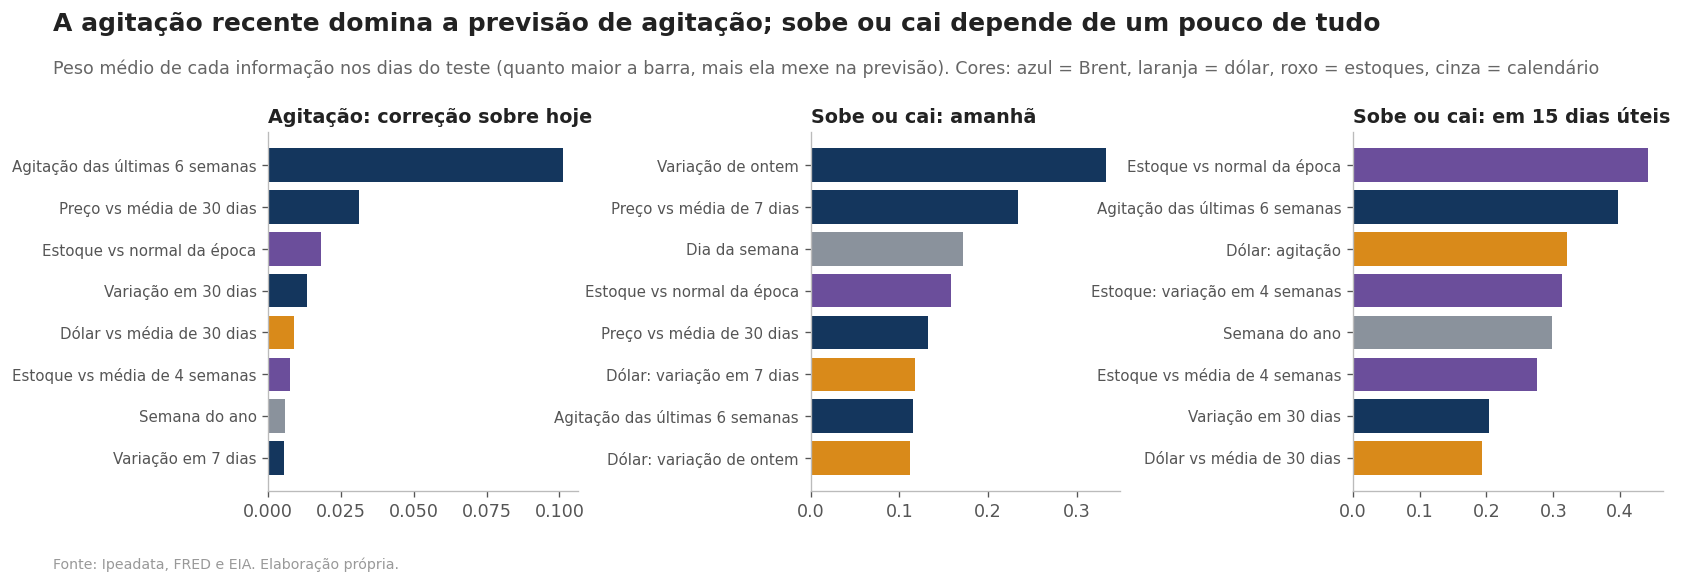

In [19]:
T0 = int(np.argmax((DS["data"] >= TE_INI).values)); ROT = [NOMES[f] for f in FEAT]
def shap_de(tipo, h):
    if tipo == "agit": m = lgb.LGBMRegressor(**P_AG, random_state=SEMENTE, verbose=-1, n_jobs=N_JOBS); yv, hh = Y_DELTA, H
    else: m = lgb.LGBMClassifier(**P_DIR, random_state=SEMENTE, verbose=-1, n_jobs=N_JOBS); yv, hh = Y_UP[h], h
    tr = np.arange(INI, T0 - hh + 1); m.fit(X[tr], yv[tr] if tipo == "agit" else yv[tr].astype(int)); te = origens(TE_INI, FIM, hh); sv = m.predict(X[te], pred_contrib=True)[:, :-1]                      # SHAP exato (TreeSHAP) calculado pelo próprio LightGBM
    return dict(m=m, sv=np.asarray(sv), X=X[te], hoje=X[-1:])
SH = {"agit": shap_de("agit", H), "dir1": shap_de("dir", 1), "dir15": shap_de("dir", 15)}
def barras(ax, d, titulo, n=8):
    imp = pd.Series(np.abs(d["sv"]).mean(axis=0), index=FEAT).sort_values().tail(n); ax.barh([NOMES[f] for f in imp.index], imp.values, color=[CORG[GRUPO[f]] for f in imp.index]); ax.set_title(titulo, fontsize=11.5, loc="left", fontweight="bold"); ax.grid(axis="y", visible=False)
fig, axs = moldura((14, 4.9), "A agitação recente domina a previsão de agitação; sobe ou cai depende de um pouco de tudo", "Peso médio de cada informação nos dias do teste (quanto maior a barra, mais ela mexe na previsão). Cores: azul = Brent, laranja = dólar, roxo = estoques, cinza = calendário", ncols=3)
barras(axs[0], SH["agit"], "Agitação: correção sobre hoje"); barras(axs[1], SH["dir1"], "Sobe ou cai: amanhã"); barras(axs[2], SH["dir15"], "Sobe ou cai: em 15 dias úteis")
for a in axs: a.tick_params(axis="y", labelsize=9); a.set_xlabel("")
fig.subplots_adjust(wspace=0.75, left=0.14); plt.show()

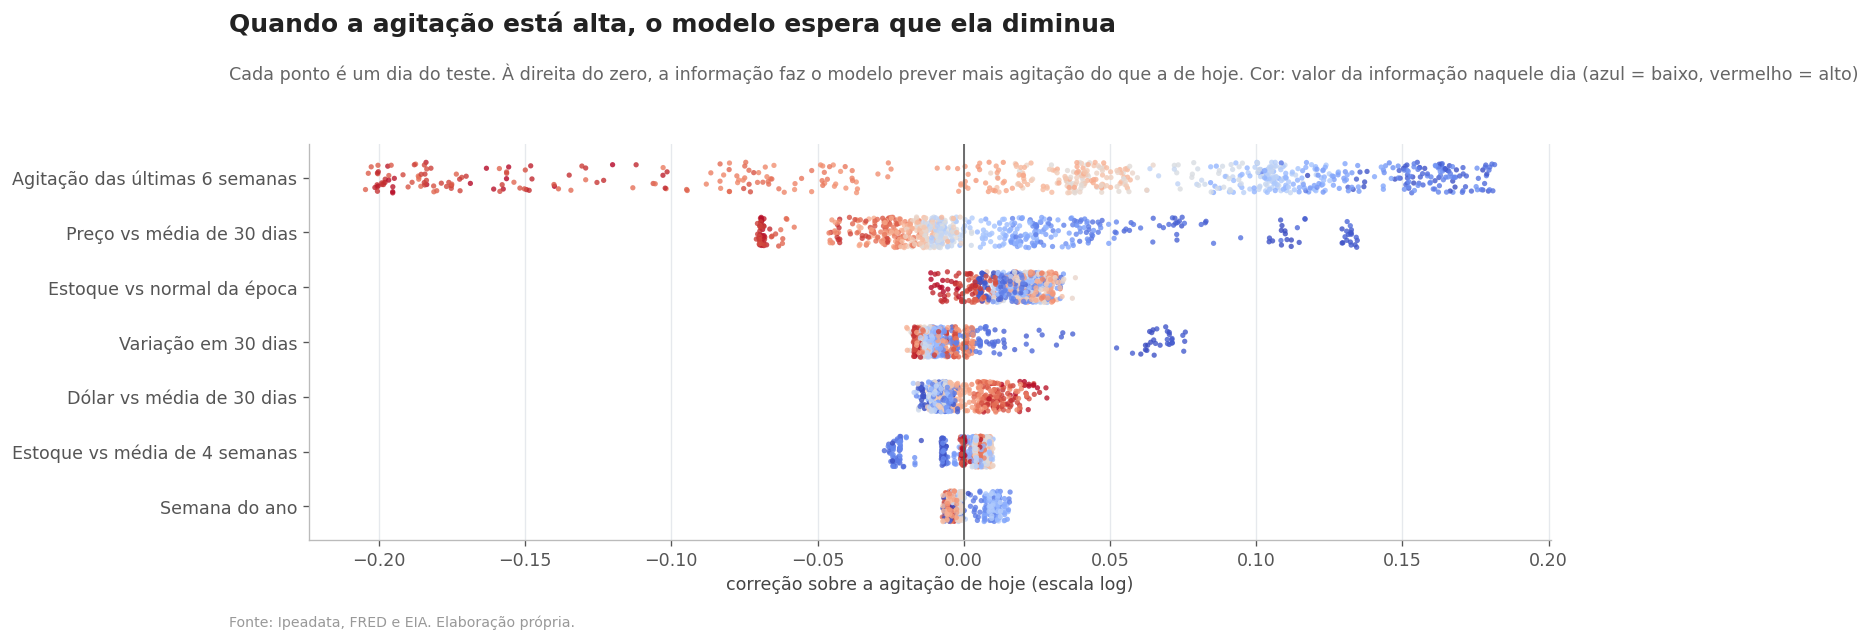

In [20]:
d = SH["agit"]; sv, Xs = d["sv"], d["X"]; ordem = np.argsort(np.abs(sv).mean(axis=0))[::-1][:7][::-1]; rg = np.random.default_rng(SEMENTE)
fig, ax = moldura((11.5, 5.4), "Quando a agitação está alta, o modelo espera que ela diminua", "Cada ponto é um dia do teste. À direita do zero, a informação faz o modelo prever mais agitação do que a de hoje. Cor: valor da informação naquele dia (azul = baixo, vermelho = alto)")
for k, j in enumerate(ordem):
    ax.scatter(sv[:, j], k + rg.uniform(-0.28, 0.28, len(sv)), c=pd.Series(Xs[:, j]).rank(pct=True).values, cmap="coolwarm", s=10, alpha=0.8, linewidths=0)
ax.axvline(0, color="#555", lw=1); ax.set_yticks(range(len(ordem))); ax.set_yticklabels([ROT[j] for j in ordem]); ax.grid(axis="x", color="#e6e9ed"); ax.grid(axis="y", visible=False); ax.set_xlabel("correção sobre a agitação de hoje (escala log)"); plt.show()

**O que vemos**
- **Agitação:** a **agitação das últimas 6 semanas** é de longe a informação mais importante. O gráfico mostra o porquê: quando ela está **alta** (vermelho), o modelo **corrige para baixo**; quando está **baixa** (azul), corrige para cima. Ele aprendeu que a agitação **volta à média**.
- **Sobe ou cai:** o peso se espalha por muitas informações, sem uma dominante (variação de ontem, estoque, calendário...). É o padrão de um modelo que não achou sinal.

## 12. A previsão de hoje

In [21]:
# treino final com todos os dados disponíveis (só amostras cujo resultado já aconteceu) e previsão a partir do último fechamento
N = len(DS); DATA_HOJE = DS["data"].iloc[-1]; P0 = float(PRECO[-1]); xh = X[-1:]
M_AG = lgb.LGBMRegressor(**P_AG, random_state=SEMENTE, verbose=-1, n_jobs=N_JOBS).fit(X[np.arange(INI, N - H)], Y_DELTA[np.arange(INI, N - H)])
M_DIR = {h: lgb.LGBMClassifier(**P_DIR, random_state=SEMENTE, verbose=-1, n_jobs=N_JOBS).fit(X[np.arange(INI, N - h)], Y_UP[h][np.arange(INI, N - h)].astype(int)) for h in HD}
# calibração das probabilidades (Platt) com as previsões fora da amostra da validação e do teste
lg = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
CAL = {h: LogisticRegression(C=1e6).fit(lg(np.r_[DIR[("validação", h)]["p"], DIR[("teste", h)]["p"]]).reshape(-1, 1), np.r_[DIR[("validação", h)]["y"], DIR[("teste", h)]["y"]]) for h in HD}
Zf = np.r_[RV["z"], RT["z"]]; QF = {"80%": np.quantile(Zf, [0.10, 0.90]), "95%": np.quantile(Zf, [0.025, 0.975])}
vol_hoje = float(DS["brent_desv_pad_30d"].iloc[-1]); sg_hoje = float(vol_hoje * np.exp(M_AG.predict(xh)[0])) if ESC == "modelo" else vol_hoje
ref = np.exp(Y_AG[INI:N - H - 1]); pct_hoje = float((ref < sg_hoje).mean() * 100); fase_hoje = FASE(np.log(np.array([sg_hoje])))[0]
datas = pd.bdate_range(DATA_HOJE + pd.Timedelta(days=1), periods=H); PREV = pd.DataFrame({"h": np.arange(1, H + 1), "data": datas})
for k, q in QF.items(): PREV[f"inf_{k[:-1]}"], PREV[f"sup_{k[:-1]}"] = P0 * np.exp(q[0] * sg_hoje * np.sqrt(PREV["h"]) / 100), P0 * np.exp(q[1] * sg_hoje * np.sqrt(PREV["h"]) / 100)
PROB = {h: float(CAL[h].predict_proba(lg(M_DIR[h].predict_proba(xh)[:, 1]).reshape(-1, 1))[0, 1]) for h in HD}
print(f"{DATA_HOJE:%d/%m/%Y}: preço US$ {P0:.2f} | agitação prevista {sg_hoje:.2f}% ao dia ({fase_hoje}, mais agitado que {pct_hoje:.0f}% da história) | agitação das últimas 6 semanas {vol_hoje:.2f}%")
print("Probabilidade de o preço estar acima do de hoje:", {f"{h} dia(s)": f"{p:.0%}" for h, p in PROB.items()})

29/09/2026: preço US$ 113.96 | agitação prevista 3.15% ao dia (moderado, mais agitado que 77% da história) | agitação das últimas 6 semanas 3.90%
Probabilidade de o preço estar acima do de hoje: {'1 dia(s)': '53%', '5 dia(s)': '51%', '15 dia(s)': '49%'}


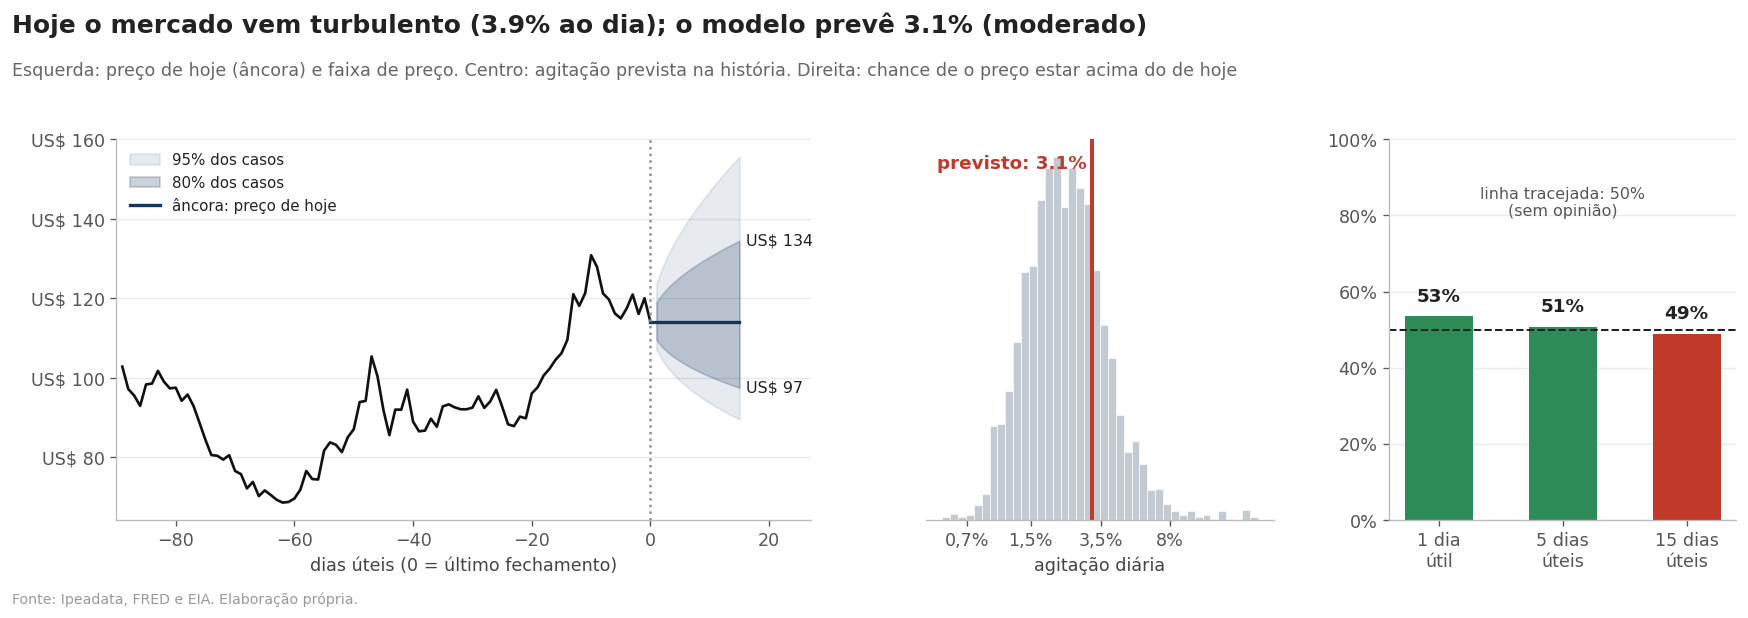

In [22]:
hist = DS.iloc[-90:]; fig, axs = moldura((15, 5.2), f"Hoje o mercado vem turbulento ({vol_hoje:.1f}% ao dia); o modelo prevê {sg_hoje:.1f}% ({fase_hoje})", "Esquerda: preço de hoje (âncora) e faixa de preço. Centro: agitação prevista na história. Direita: chance de o preço estar acima do de hoje", ncols=3, gridspec_kw={"width_ratios": [2.2, 1.1, 1.1]})
ax = axs[0]; xf = PREV["h"].values; ax.plot(np.arange(-len(hist) + 1, 1), hist["brent_preco"].values, color="#111", lw=1.6)
ax.fill_between(xf, PREV["inf_95"], PREV["sup_95"], color=COR["preco"], alpha=0.10, label="95% dos casos"); ax.fill_between(xf, PREV["inf_80"], PREV["sup_80"], color=COR["preco"], alpha=0.22, label="80% dos casos"); ax.plot([0, H], [P0, P0], color=COR["preco"], lw=2, label="âncora: preço de hoje")
ax.axvline(0, color=COR["neutro"], ls=":"); usd(ax); ax.set_xlabel("dias úteis (0 = último fechamento)"); ax.legend(loc="upper left", fontsize=9)
ax.annotate(f"US$ {PREV['inf_80'].iloc[-1]:.0f}", (H, PREV["inf_80"].iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=9.5, va="center"); ax.annotate(f"US$ {PREV['sup_80'].iloc[-1]:.0f}", (H, PREV["sup_80"].iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=9.5, va="center"); ax.set_xlim(-90, H + 12)
ax = axs[1]; ax.hist(np.log10(ref), bins=40, color="#c4cad2", edgecolor="white", lw=0.4); ax.axvline(np.log10(sg_hoje), color=COR["queda"], lw=2.4); ax.set_yticks([]); ax.grid(False); ax.spines["left"].set_visible(False)
ax.set_xticks(np.log10([0.7, 1.5, 3.5, 8])); ax.set_xticklabels(["0,7%", "1,5%", "3,5%", "8%"]); ax.set_xlabel("agitação diária"); ax.text(0.03, 0.96, f"previsto: {sg_hoje:.1f}%", transform=ax.transAxes, color=COR["queda"], ha="left", va="top", fontsize=11, fontweight="bold")
ax = axs[2]; v = [PROB[h] * 100 for h in HD]; ax.bar([f"{h} dia\nútil" if h == 1 else f"{h} dias\núteis" for h in HD], v, color=[COR["alta"] if x >= 50 else COR["queda"] for x in v], width=0.55); ax.axhline(50, color="#222", ls="--", lw=1.2)
for k, x in enumerate(v): ax.text(k, x + 4, f"{x:.0f}%", ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, 100); pct(ax); ax.text(0.5, 0.80, "linha tracejada: 50%\n(sem opinião)", transform=ax.transAxes, ha="center", fontsize=9.5, color="#555"); plt.show()

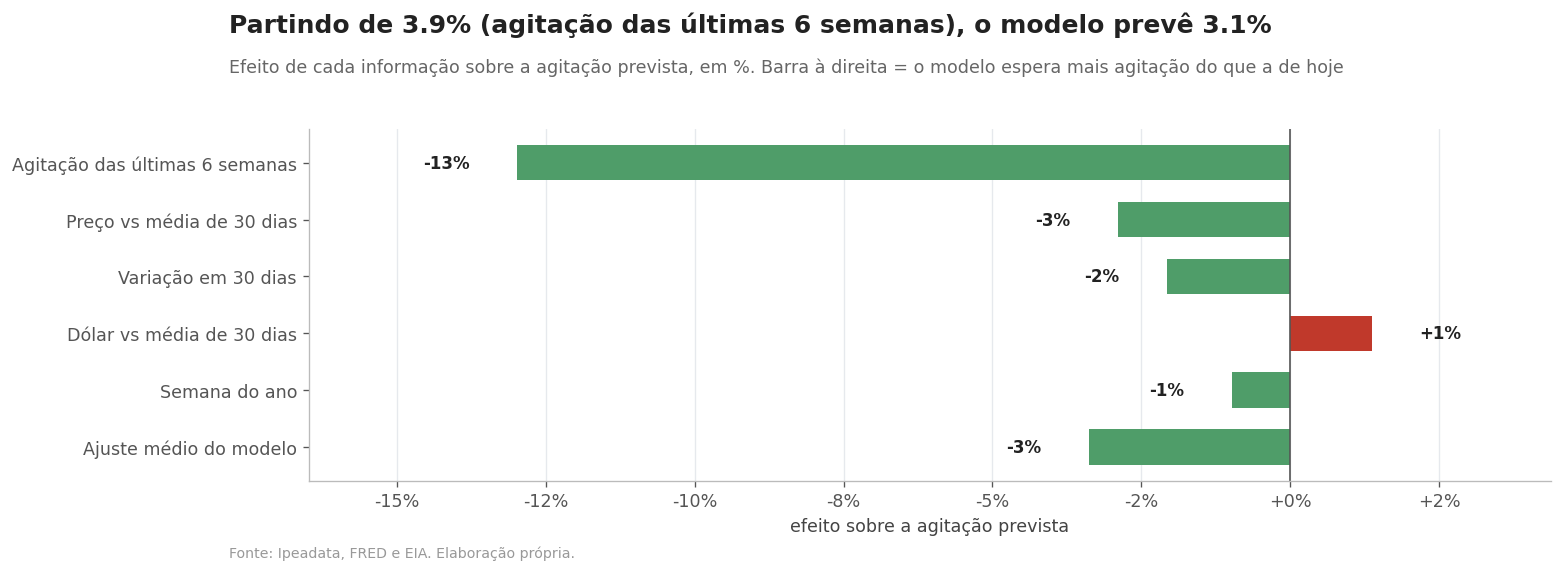

In [23]:
c = M_AG.predict(xh, pred_contrib=True)[0]; efeito = (np.exp(c[:-1]) - 1) * 100; ajuste = (np.exp(c[-1]) - 1) * 100; pm = vol_hoje * np.exp(c.sum())      # efeito de cada informação, em % sobre a agitação de hoje
ordem = list(np.argsort(np.abs(efeito))[::-1][:5][::-1]); nomes = ["Ajuste médio do modelo"] + [NOMES[FEAT[j]] for j in ordem]; vals = [ajuste] + [efeito[j] for j in ordem]
fig, ax = moldura((11.5, 4.8), f"Partindo de {vol_hoje:.1f}% (agitação das últimas 6 semanas), o modelo prevê {pm:.1f}%", "Efeito de cada informação sobre a agitação prevista, em %. Barra à direita = o modelo espera mais agitação do que a de hoje")
ax.barh(nomes, vals, color=[COR["queda"] if v > 0 else COR["calmo"] for v in vals], height=0.62)
for k, v in enumerate(vals): ax.text(v + (0.8 if v > 0 else -0.8), k, f"{v:+.0f}%", va="center", ha="left" if v > 0 else "right", fontsize=10, fontweight="bold")
ax.set_xlim(min(vals) - 3.5, max(max(vals), 0) + 3); ax.axvline(0, color="#555", lw=1); ax.grid(axis="x", color="#e6e9ed"); ax.grid(axis="y", visible=False); ax.set_xlabel("efeito sobre a agitação prevista"); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:+.0f}%")); plt.show()

**Leitura de hoje (29/09/2026)**
- O mercado **vem turbulento** (3,9% ao dia nas últimas 6 semanas), e o modelo espera que a agitação **diminua um pouco**, para 3,1% ao dia.
- Faixa de 80% em 15 dias úteis: **de US$ 97 a US$ 134**, em torno do preço de hoje (US$ 114).
- Chance de o preço estar acima do de hoje: 53%, 51% e 49% (1, 5 e 15 dias úteis). Perto de 50% significa **sem opinião**.

In [24]:
# dados da previsão de hoje, para alimentar o app (simulador e painel)
APP = ART.parent.parent / "02_App"
json.dump({"data_hoje": f"{DATA_HOJE:%Y-%m-%d}", "preco_hoje": P0, "agitacao_6s": vol_hoje, "agitacao_prevista": sg_hoje, "fase_hoje": str(fase_hoje), "percentil_hoje": pct_hoje,
           "fatores": {k: [float(q[0]), float(q[1])] for k, q in QF.items()}, "prob_acima": {str(h): p for h, p in PROB.items()}, "limites_fase": [1.5, 3.5],
           "distribuicao_agitacao": {str(q): float(np.quantile(ref, q)) for q in (0.05, 0.25, 0.5, 0.75, 0.95)},
           "historico": {"datas": [f"{d:%Y-%m-%d}" for d in pd.to_datetime(DATAS[-120:])], "preco": [float(x) for x in PRECO[-120:]]},
           "previsao": [{"h": int(r.h), "data": f"{r.data:%Y-%m-%d}", "inf80": float(r.inf_80), "sup80": float(r.sup_80), "inf95": float(r.inf_95), "sup95": float(r.sup_95)} for r in PREV.itertuples()],
           "replay": {"fatores_val": {"80%": [float(Q80[0]), float(Q80[1])], "95%": [float(Q95[0]), float(Q95[1])]}, "datas": [f"{x:%Y-%m-%d}" for x in pd.to_datetime(AG["teste"]["data"])], "sigma": [round(float(x), 4) for x in np.exp(AG["teste"]["modelo"])]},
           "efeitos_hoje": {NOMES[FEAT[j]]: float(efeito[j]) for j in np.argsort(np.abs(efeito))[::-1][:5]}}, open(APP / "dados_notebook.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
print("dados do app gravados em", APP)

dados do app gravados em C:\Users\vinic\OneDrive\Área de Trabalho\TC - 04 SUB\02_App


## 13. Conclusão

- **O preço de hoje é a âncora.** Nenhum modelo supera "amanhã = hoje" como previsão de preço, e **sobe ou cai** não é previsível com estes dados (AUC de 0,45 a 0,47 no teste).
- **O que dá para prever é a agitação.** O modelo melhora pouco a âncora ("a agitação de hoje continua"), mas aprende que a agitação alta tende a diminuir e entrega uma **faixa de preço** que cobre 76% dos casos (73% nas fases turbulentas, contra 44% de uma faixa fixa).
- **Como usar:** a faixa como margem de segurança em análises de compra, venda e proteção; a fase do mercado como termômetro; o SHAP para explicar por que a previsão é essa.
- **Limites:** o modelo reage depois das viradas bruscas, a faixa fica estreita demais nas fases estáveis, e choques geopolíticos, como os de 2026, escapam de qualquer faixa.